# El número y la palabra · Braga 2026
Francisco Javier Muñoz-Acebes · Universidad de Valladolid

Sube los dos TXT depurados al directorio de trabajo o a `textos/`, y ejecuta las celdas en orden. Se verifica su SHA-256. `limpieza.json` documenta los originales y las 15 capitulares recompuestas. Serie principal: formas de dos o más letras, NFC, minúsculas, diacríticos conservados, apóstrofos y guiones separan tokens. Se mantiene el umbral del estudio original por comparabilidad; al final se comprueba su efecto y se contrasta con Mâze sin umbral. MHGTagger es opcional y está desactivado por defecto; resultados de anotación previos se identifican como históricos. La edición exacta de Tristan no consta en el fichero facilitado.

## 0 · Preparación

In [1]:

# ─────────────  CONFIGURACIÓN  ─────────────

# ─────────────  CONFIGURACIÓN  ─────────────

import os
import re
import unicodedata
import urllib.request

# Los textos se toman del repositorio público, de modo que el cuaderno se
# ejecuta igual lo abra quien lo abra y sin pedir acceso a Google Drive.
# Si hay un Drive montado con la carpeta Braga_2026, se usa esa copia.

from pathlib import Path
import hashlib, platform
ARCHIVOS={'Parzival':'parzival_depurado.txt','Tristan':'tristan_depurado.txt'}
HASHES={'Parzival': '2843cc2bea267543896f8ea5522b73e545a25b429b450e57ddcf0276e6b8ea46', 'Tristan': 'ffa53649c69ecbb438e0418536f21282022770bcc2c3fb9b8570ddbcf92617b0'}
SALIDA='figuras_braga'
COLOR={'Parzival':'#A62F42','Tristan':'#2E6FB5'}
INK,MUTED,GRID='#1E2A38','#5B6572','#DCE0E4'
def localizar(nombre):
    for carpeta in (Path('textos'),Path('.'),Path('/content')):
        ruta=carpeta/nombre
        if ruta.is_file(): return str(ruta)
    raise FileNotFoundError('Sube '+nombre+' a textos/ o al directorio de trabajo')
RUTAS={o:localizar(a) for o,a in ARCHIVOS.items()}
for o,r in RUTAS.items():
    assert hashlib.sha256(Path(r).read_bytes()).hexdigest()==HASHES[o], 'Corpus distinto: '+o
os.makedirs(SALIDA,exist_ok=True)
print('Python',platform.python_version())

# ─────────────  NORMALIZACIÓN  ─────────────

def normalizar_nombre(texto):
    """
    Normaliza nombres:
    - minúsculas
    - Unicode
    - eliminación de diacríticos
    - conservación de letras
    """

    texto = texto.casefold()
    texto = texto.replace('ſ', 's')

    texto = unicodedata.normalize('NFD', texto)

    texto = ''.join(
        caracter
        for caracter in texto
        if unicodedata.category(caracter) != 'Mn'
    )

    return unicodedata.normalize('NFC', texto)


# ─────────────  RAÍCES DE PERSONAJES  ─────────────

RAICES = {

    'Parzival': {

        'Parzival': [
            'parzival',
            'parcival',
            'percival',
            'perceval',
            'parsifal',
            'parsival',
            'parzifal',
            'perzival',
            'parcifal',
            'peredur'
        ],

        'Gâwân': [
            'gawan',
            'gawein',
            'gawain',
            'gauvain',
            'gavain',
            'walwein',
            'walwan'
        ],

        'Feirefîz': [
            'feirefiz',
            'feirefis',
            'feirefys'
        ],

        'Anfortas': [
            'anfortas',
            'amfortas',
            'anforte',
            'amforte'
        ],

        'Cundrie': [
            'cundri',
            'kundri',
            'kundry'
        ],

        'Condwîrâmûrs': [
            'condwiramurs',
            'cundwiramurs'
        ],

        'Gurnemanz': [
            'gurnemanz',
            'gurnemans'
        ],

        'Trevrizent': [
            'trevrizent',
            'trevrizents'
        ]
    },


    'Tristan': {

        'Tristan': [
            'tristan',
            'tristran',
            'tristrant',
            'tristram',
            'tristrem',
            'tristano',
            'tristao',
            'tantris'
        ],

        'Îsôt': [
            'isot',
            'isold',
            'isolt',
            'isolde',
            'isaut',
            'iseut',
            'yseut',
            'yseult',
            'ysolt',
            'ysolde',
            'isoude',
            'isalde',
            'izolda'
        ],

        'Marke': [
            'marke',
            'markes',
            'marc',
            'march'
        ],

        'Brangæne': [
            'brangaen',
            'brangen',
            'brangaene',
            'brangene',
            'brangæne'
        ],

        'Riwalîn': [
            'riwalin',
            'riwalîn',
            'rivalin'
        ],

        'Blanscheflûr': [
            'blanschefl',
            'blanchefl',
            'blancheflor'
        ],

        'Rûal': [
            'rual',
            'ruwal'
        ],

        'Môrolt': [
            'morolt',
            'morold',
            'morholt',
            'morol'
        ]
    }
}


# ─────────────  NORMALIZAR LAS RAÍCES  ─────────────

RAICES_NORMALIZADAS = {

    obra: {
        personaje: [
            normalizar_nombre(raiz)
            for raiz in variantes
        ]
        for personaje, variantes in personajes.items()
    }

    for obra, personajes in RAICES.items()
}


# ─────────────  COMPILAR PATRONES  ─────────────

PATRONES_PERSONAJES = {

    obra: {

        personaje: re.compile(
            r'(?<![^\W\d_])(?:'
            + '|'.join(
                re.escape(raiz)
                for raiz in sorted(set(variantes), key=len, reverse=True)
            )
            + r')[^\W\d_]*',
            flags=re.UNICODE
        )

        for personaje, variantes in personajes.items()

    }

    for obra, personajes in RAICES_NORMALIZADAS.items()
}


print("Configuración cargada correctamente.")
for obra, ruta in RUTAS.items():
    tamano = f'{os.path.getsize(ruta):,}'.replace(',', '.')
    print(f"  {obra}: {ruta} ({tamano} bytes)")
print(f"Carpeta de salida: {SALIDA}")

Python 3.13.5
Configuración cargada correctamente.
  Parzival: textos/parzival_depurado.txt (748.757 bytes)
  Tristan: textos/tristan_depurado.txt (568.468 bytes)
Carpeta de salida: figuras_braga


In [2]:
# ─────────────  ENTORNO, TOKENIZADOR Y CARGA  ─────────────
import os, re, math, random, unicodedata
from collections import Counter
import numpy as np, matplotlib, matplotlib.pyplot as plt

os.makedirs(SALIDA, exist_ok=True)
random.seed(7); np.random.seed(7)

matplotlib.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 220, 'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
    'font.size': 12, 'axes.titlesize': 15, 'axes.labelsize': 12,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'legend.frameon': False, 'figure.facecolor': 'white',
})

def marco(ax, titulo=None, x=None, y=None, rejilla='y'):
    """Ejes sobrios: rejilla en un solo sentido y título a la izquierda."""
    if titulo: ax.set_title(titulo, loc='left', color=INK, fontweight='bold', pad=14)
    if x: ax.set_xlabel(x)
    if y: ax.set_ylabel(y)
    ax.grid(axis=rejilla, alpha=0.9); ax.set_axisbelow(True)
    return ax

def guardar(fig, nombre):
    ruta = os.path.join(SALIDA, nombre)
    fig.savefig(ruta); print('→', ruta); return ruta

def mil(n):
    return f'{n:,}'.replace(',', '.')

_EQUIV = str.maketrans({'æ': 'ae', 'œ': 'oe', 'ß': 'ss', 'ſ': 's'})

def sin_diacriticos(w):
    """minúsculas sin tildes ni ligaduras: îsôt → isot, brangæne → brangaene."""
    w = w.translate(_EQUIV)
    return ''.join(c for c in unicodedata.normalize('NFD', w) if unicodedata.category(c) != 'Mn')

# ── tokenización para alto alemán medio ──
# Conserva î â ê û ô æ œ y trata cada verso por separado: el salto de línea
# es un límite de palabra, no un carácter que se elimina.
LETRAS = r"a-zà-öø-ÿāēīōūăĕĭŏŭǣœæ"
RE_TOKEN = re.compile(f"[{LETRAS}]+", re.IGNORECASE)
RE_NUM_VERSO = re.compile(r"^\s*\d+[.)\t ]")

def tokenizar(texto, minimo=2):
    texto = unicodedata.normalize('NFC', texto.replace('\u00a0', ' ').replace('ſ', 's'))
    lineas = [RE_NUM_VERSO.sub('', l) for l in texto.split('\n')]
    toks = RE_TOKEN.findall(' '.join(lineas).lower())
    return [t for t in toks if len(t) >= minimo]

TOK, FRQ = {}, {}
for obra, ruta in RUTAS.items():
    with open(ruta, encoding='utf-8', errors='strict') as f:
        TOK[obra] = tokenizar(f.read())
    FRQ[obra] = Counter(TOK[obra])

print(f"{'':10s} {'tokens':>9} {'formas':>9} {'TTR':>7}")
for obra in TOK:
    print(f'{obra:10s} {mil(len(TOK[obra])):>9} {mil(len(FRQ[obra])):>9} '
          f'{len(FRQ[obra])/len(TOK[obra]):>7.3f}')


              tokens    formas     TTR
Parzival     130.330    10.815   0.083
Tristan      101.082     7.772   0.077


## 1 · Las palabras más frecuentes

El punto de partida de todo lo demás. La tabla da los veinte primeros puestos de cada obra; la
figura compara, para las quince palabras más frecuentes del conjunto, cuántas veces aparece cada
una por cada mil palabras, que es la cifra que permite comparar textos de distinta longitud.

Lo que interesa no es tanto la lista como su composición.


Veinte palabras más frecuentes

     Parzival                 Tristan       
  1  der               3428   und               3599
  2  daz               2523   daz               2831
  3  ir                2366   ir                2186
  4  er                2128   der               2178
  5  ich               1874   er                2006
  6  in                1638   in                1702
  7  si                1547   an                1536
  8  von               1490   unde              1433
  9  den               1477   ich               1332
 10  die               1473   diu               1124
 11  dâ                1387   die               1113
 12  sîn               1369   sô                1079
 13  mit               1337   mit               1056
 14  und               1319   ze                 969
 15  was               1308   von                963
 16  diu               1227   dâ                 952
 17  ein               1197   sîn                884
 18  des              

→ figuras_braga/fig9_frecuencias.png


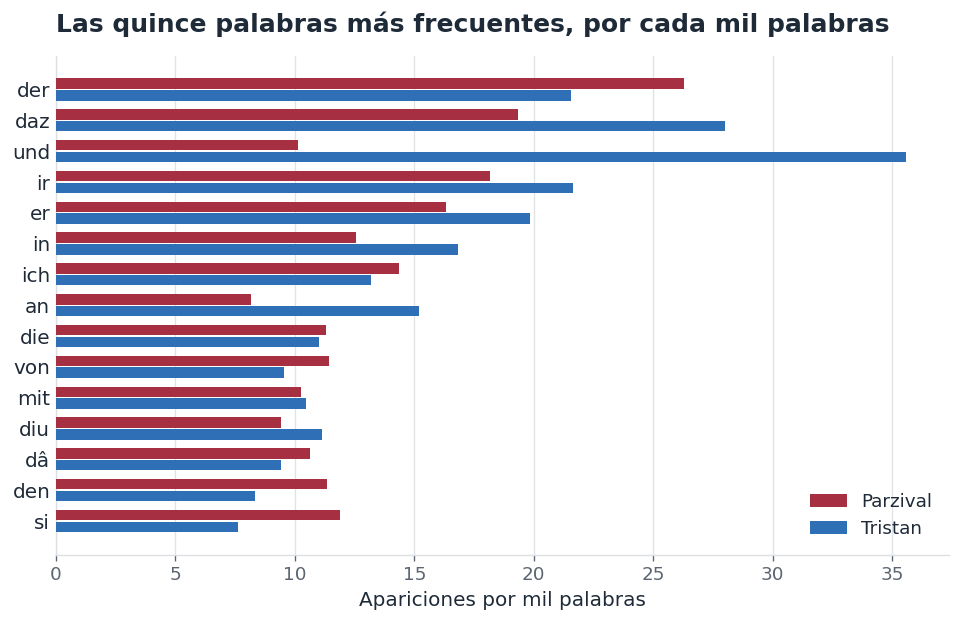


DATO
  Parzival: der · daz · ir · er · ich · in · si · von · den · die
  Tristan: und · daz · ir · der · er · in · an · unde · ich · diu
  En los veinte primeros puestos de ambas obras no hay un solo sustantivo, verbo ni adjetivo:
  solo artículos, pronombres, preposiciones y conjunciones.


In [3]:
# ─────────────  1. PALABRAS MÁS FRECUENTES  ─────────────
N_TABLA, N_FIG = 20, 15

print('Veinte palabras más frecuentes\n')
filas = {o: FRQ[o].most_common(N_TABLA) for o in TOK}
print(f"{'':>3}  {'Parzival':<14}{'':>8}   {'Tristan':<14}")
for i in range(N_TABLA):
    p, t = filas['Parzival'][i], filas['Tristan'][i]
    print(f'{i+1:>3}  {p[0]:<14}{p[1]:>8}   {t[0]:<14}{t[1]:>8}')

# frecuencia por mil palabras de las N_FIG más frecuentes del conjunto
conjunto = Counter()
for o in TOK: conjunto.update(TOK[o])
top = [w for w, _ in conjunto.most_common(N_FIG)]
tasa = {o: [1000 * FRQ[o].get(w, 0) / len(TOK[o]) for w in top] for o in TOK}

fig, ax = plt.subplots(figsize=(9.6, 5.4))
y = np.arange(len(top))[::-1]
alto = 0.38
for i, o in enumerate(TOK):
    ax.barh(y + (0.5 - i) * alto, tasa[o], height=alto - 0.04, color=COLOR[o], label=o, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(top, fontsize=12, color=INK)
ax.tick_params(axis='y', length=0)
marco(ax, 'Las quince palabras más frecuentes, por cada mil palabras', 'Apariciones por mil palabras', None, rejilla='x')
ax.legend(loc='lower right', fontsize=11)
guardar(fig, 'fig9_frecuencias.png'); plt.show()

print('\nDATO')
for o in TOK:
    print(f'  {o}: ' + ' · '.join(w for w, _ in filas[o][:10]))
print('  En los veinte primeros puestos de ambas obras no hay un solo sustantivo, verbo ni adjetivo:')
print('  solo artículos, pronombres, preposiciones y conjunciones.')


## 2 · La ley de Zipf

Ordenadas las palabras de mayor a menor frecuencia, la frecuencia resulta ser aproximadamente
inversamente proporcional al rango. En escala logarítmica doble eso se ve como una recta de
pendiente cercana a −1.

El ajuste se hace sobre los rangos 10 a 1000, que es la zona donde la ley se comporta mejor. La
recta gris es la versión ideal, con exponente exactamente 1.


→ figuras_braga/fig1_zipf.png


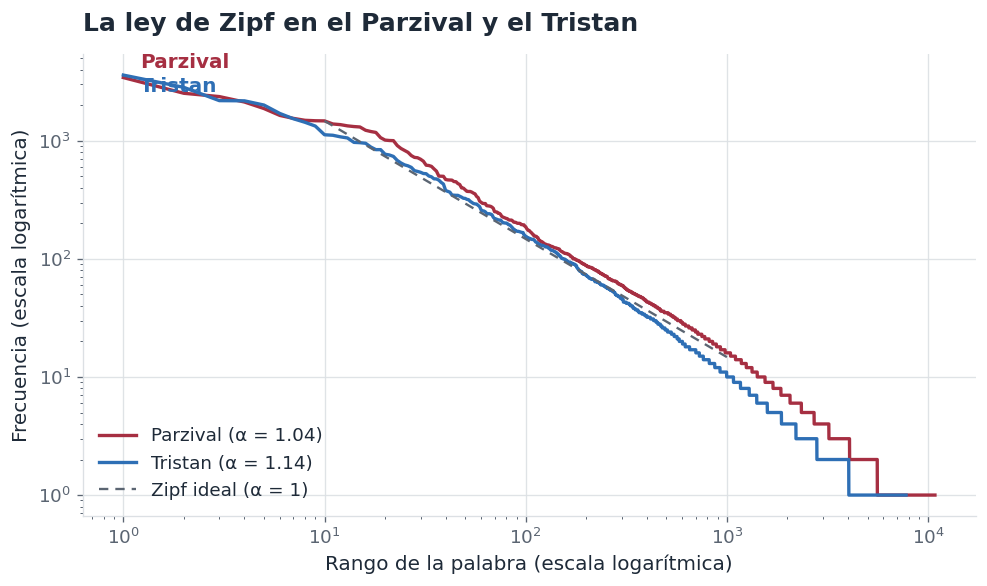


DATO
  Parzival: α = 1.04 · 1.ª der (3428), 2.ª daz (2523), 3.ª ir (2366)
      la 2.ª es el 74% de la 1.ª y la 3.ª el 69% (la ley ideal predice 50% y 33%)
  Tristan: α = 1.14 · 1.ª und (3599), 2.ª daz (2831), 3.ª ir (2186)
      la 2.ª es el 79% de la 1.ª y la 3.ª el 61% (la ley ideal predice 50% y 33%)


In [4]:
# ─────────────  2. LEY DE ZIPF  ─────────────
fig, ax = plt.subplots(figsize=(9.6, 5.0))
zipf = {}
for k, obra in enumerate(TOK):
    f = np.array(sorted(FRQ[obra].values(), reverse=True), dtype=float)
    r = np.arange(1, len(f) + 1)
    m = (r >= 10) & (r <= min(1000, len(f)))
    pend, _ = np.polyfit(np.log10(r[m]), np.log10(f[m]), 1)
    zipf[obra] = -pend
    ax.loglog(r, f, color=COLOR[obra], lw=2, label=f'{obra} (α = {-pend:.2f})')
    ax.annotate(obra, (r[0], f[0]), xytext=(10, 6 - 16 * k), textcoords='offset points',
                color=COLOR[obra], fontweight='bold', fontsize=12)

r0 = np.array([10, 1000.0])
f0 = FRQ['Parzival'].most_common(10)[-1][1] * (r0 / 10.0) ** -1
ax.loglog(r0, f0, color=MUTED, lw=1.4, ls=(0, (4, 3)), label='Zipf ideal (α = 1)')
marco(ax, 'La ley de Zipf en el Parzival y el Tristan',
      'Rango de la palabra (escala logarítmica)', 'Frecuencia (escala logarítmica)', rejilla='both')
ax.legend(loc='lower left', fontsize=11)
guardar(fig, 'fig1_zipf.png'); plt.show()

print('\nDATO')
for obra in TOK:
    t = FRQ[obra].most_common(3)
    print(f'  {obra}: α = {zipf[obra]:.2f} · 1.ª {t[0][0]} ({t[0][1]}), '
          f'2.ª {t[1][0]} ({t[1][1]}), 3.ª {t[2][0]} ({t[2][1]})')
    print(f'      la 2.ª es el {t[1][1]/t[0][1]:.0%} de la 1.ª y la 3.ª el {t[2][1]/t[0][1]:.0%} '
          f'(la ley ideal predice 50% y 33%)')


## 3 · Riqueza léxica: TTR, STTR y MTLD

El Type-Token Ratio —formas distintas dividido entre palabras totales— es la medida más intuitiva
de riqueza léxica y también la más engañosa: cae sin parar a medida que el texto crece, porque un
texto largo repite inevitablemente más palabras.

La curva lo muestra. Las alternativas que controlan la longitud son el **STTR**, que promedia el TTR
de ventanas de mil palabras, y el **MTLD**, que mide cuántas palabras se pueden leer de media antes
de que la diversidad caiga por debajo de un umbral.


→ figuras_braga/fig3_ttr.png


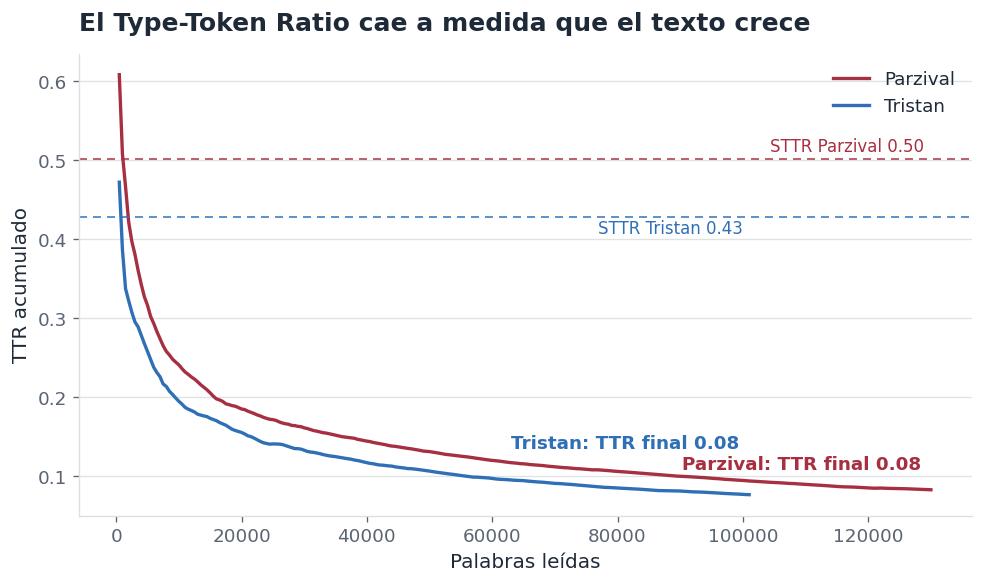


DATO
               Parzival    Tristan
palabras        130.330    101.082
TTR global        0.083      0.077
STTR (1.000)      0.501      0.428
MTLD                193        106
  El TTR global da prácticamente el mismo valor para dos textos de longitud muy distinta.
  Las medidas que controlan la longitud sí los separan: ahí está el aviso metodológico.


In [5]:
# ─────────────  3. RIQUEZA LÉXICA  ─────────────
def mtld_pass(toks, umbral=0.72):
    vistos=set(); n=0; factores=0.0
    for t in toks:
        n+=1; vistos.add(t)
        if len(vistos)/n <= umbral:
            factores+=1; vistos=set(); n=0
    if n: factores+=(1-len(vistos)/n)/(1-umbral)
    return len(toks)/factores if factores else float('nan')
def mtld(toks): return (mtld_pass(toks)+mtld_pass(toks[::-1]))/2


def curva_ttr(toks, paso=500):
    xs, ys, vistos = [], [], set()
    for i, t in enumerate(toks, 1):
        vistos.add(t)
        if i % paso == 0:
            xs.append(i); ys.append(len(vistos) / i)
    return np.array(xs), np.array(ys)

def sttr(toks, v=1000):
    tramos = [toks[i:i + v] for i in range(0, len(toks) - v + 1, v)]
    return float(np.mean([len(set(t)) / len(t) for t in tramos])) if tramos else float('nan')

fig, ax = plt.subplots(figsize=(9.6, 5.0))
riqueza = {}
for k, obra in enumerate(TOK):
    toks = TOK[obra]
    x, y = curva_ttr(toks)
    s = sttr(toks)
    riqueza[obra] = {'n': len(toks), 'ttr': len(set(toks)) / len(toks), 'sttr': s, 'mtld': mtld(toks)}
    ax.plot(x, y, color=COLOR[obra], lw=2, label=obra)
    ax.annotate(f'{obra}: TTR final {y[-1]:.2f}', (x[-1], y[-1]), xytext=(-6, 12 + 16 * k),
                textcoords='offset points', ha='right', color=COLOR[obra], fontweight='bold', fontsize=11)
    ax.axhline(s, color=COLOR[obra], lw=1.2, ls=(0, (4, 3)), alpha=0.75)
    ax.annotate(f'STTR {obra} {s:.2f}', (x[-1], s), xytext=(-4, 5 - 15 * k),
                textcoords='offset points', ha='right', color=COLOR[obra], fontsize=10)
marco(ax, 'El Type-Token Ratio cae a medida que el texto crece', 'Palabras leídas', 'TTR acumulado')
ax.legend(loc='upper right', fontsize=11)
guardar(fig, 'fig3_ttr.png'); plt.show()

print('\nDATO')
print(f"{'':12s}{'Parzival':>11}{'Tristan':>11}")
for etiq, clave, fmt in [('palabras', 'n', 'mil'), ('TTR global', 'ttr', '.3f'),
                         ('STTR (1.000)', 'sttr', '.3f'), ('MTLD', 'mtld', '.0f')]:
    v = [mil(riqueza[o][clave]) if fmt == 'mil' else format(riqueza[o][clave], fmt) for o in ('Parzival', 'Tristan')]
    print(f'{etiq:12s}{v[0]:>11}{v[1]:>11}')
print('  El TTR global da prácticamente el mismo valor para dos textos de longitud muy distinta.')
print('  Las medidas que controlan la longitud sí los separan: ahí está el aviso metodológico.')


## 4 · Hapax legomena
Proporción de formas que aparecen una vez; no es constante universal.

→ figuras_braga/fig2_hapax.png


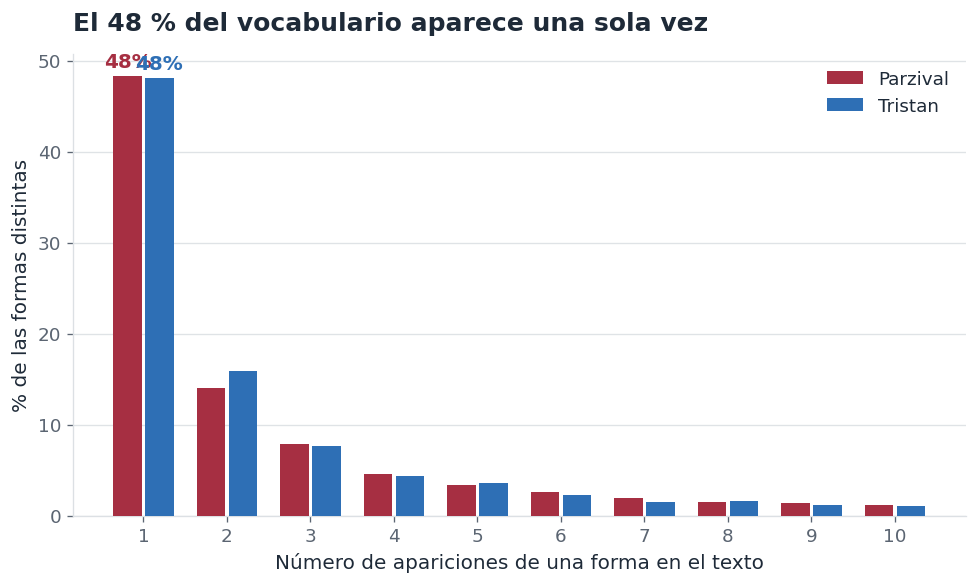


DATO
  Parzival: 5.228 hapax de 10.815 formas distintas = 48%
  Tristan: 3.741 hapax de 7.772 formas distintas = 48%

Hapax más largos de cada obra:
  Parzival: schâchzabelgesteine, unbescheidenlîche, bescheidenlîchen, unbescheidenheit, versunnenlîchiu, unverzagetlîche, ungeselleclîche, hôchverteclîche, betwungenlîchiu, entschumpfierte
  Tristan: unversprochenlîche, übercrefteclîcher, erschrockenlîche, blanschefluoren, schînbaerelîche, betwungenlîcher, bescheidenheite, vierzehenjaerec, underscheidunge, unschuldeclîche


In [6]:
# ─────────────  4. HAPAX Y ESPECTRO DE FRECUENCIAS  ─────────────
M = 10
fig, ax = plt.subplots(figsize=(9.6, 5.0))
ancho, hapax = 0.38, {}
for i, obra in enumerate(TOK):
    esp = Counter(FRQ[obra].values())
    tot = len(FRQ[obra])
    alturas = [100 * esp.get(m, 0) / tot for m in range(1, M + 1)]
    pos = np.arange(1, M + 1) + (i - 0.5) * ancho
    ax.bar(pos, alturas, width=ancho - 0.04, color=COLOR[obra], label=obra, zorder=3)
    ax.annotate(f'{alturas[0]:.0f}%', (pos[0], alturas[0]), xytext=(0, 5), textcoords='offset points',
                ha='center', color=COLOR[obra], fontweight='bold', fontsize=12)
    hapax[obra] = {'n': esp.get(1, 0), 'pct': alturas[0], 'types': tot}
ax.set_xticks(range(1, M + 1))
_p = np.mean([h['pct'] for h in hapax.values()])
marco(ax, f'El {_p:.0f} % del vocabulario aparece una sola vez',
      'Número de apariciones de una forma en el texto', '% de las formas distintas')
ax.legend(loc='upper right', fontsize=11)
guardar(fig, 'fig2_hapax.png'); plt.show()

print('\nDATO')
for obra in TOK:
    h = hapax[obra]
    print(f'  {obra}: {mil(h["n"])} hapax de {mil(h["types"])} formas distintas = {h["pct"]:.0f}%')
print('\nHapax más largos de cada obra:')
for obra in TOK:
    largos = sorted([w for w, k in FRQ[obra].items() if k == 1], key=len, reverse=True)[:10]
    print(f'  {obra}: ' + ', '.join(largos))


## 5 · Longitud de las palabras

Medida clásica de la estilometría anterior a Delta: la distribución de la longitud de las palabras
en caracteres. Dice poco sobre la autoría, pero mucho sobre el ritmo del verso, y sirve de contraste
con los métodos que vienen después.


→ figuras_braga/fig10_longitud.png


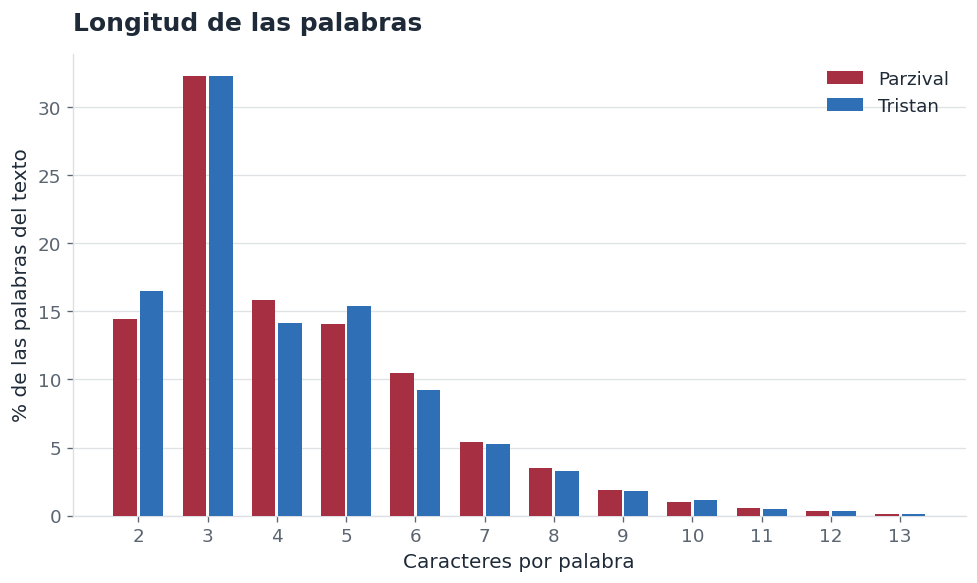


DATO
  Parzival: media 4.28 · mediana 4 · máximo 19 caracteres
  Tristan: media 4.21 · mediana 4 · máximo 18 caracteres


In [7]:
# ─────────────  5. LONGITUD DE LAS PALABRAS  ─────────────
LARGOS = {obra: np.array([len(w) for w in TOK[obra]]) for obra in TOK}
MAXL = int(max(np.percentile(L, 99.9) for L in LARGOS.values()))
fig, ax = plt.subplots(figsize=(9.6, 5.0))
ancho, longitud = 0.38, {}
for i, obra in enumerate(TOK):
    L = LARGOS[obra]
    longitud[obra] = {'media': L.mean(), 'mediana': float(np.median(L)), 'max': int(L.max())}
    alturas = [100 * np.mean(L == n) for n in range(2, MAXL + 1)]
    pos = np.arange(2, MAXL + 1) + (i - 0.5) * ancho
    ax.bar(pos, alturas, width=ancho - 0.04, color=COLOR[obra], label=obra, zorder=3)
ax.set_xticks(range(2, MAXL + 1))
marco(ax, 'Longitud de las palabras', 'Caracteres por palabra', '% de las palabras del texto')
ax.legend(loc='upper right', fontsize=11)
guardar(fig, 'fig10_longitud.png'); plt.show()

print('\nDATO')
for obra in TOK:
    d = longitud[obra]
    print(f'  {obra}: media {d["media"]:.2f} · mediana {d["mediana"]:.0f} · máximo {d["max"]} caracteres')


## 6 · Qué mide la distancia Delta

Delta toma las palabras más frecuentes del corpus, estandariza la frecuencia de cada una —es decir,
mide cuánto se desvía de la media—, resta las dos series y promedia el valor absoluto de las
diferencias. Nada más.

La figura **es** esa resta, palabra por palabra: a la izquierda las que tiran del *Tristan*, a la
derecha las que tiran del *Parzival*. Los nombres propios quedan fuera, para que la separación no se
deba a que en una obra se dice *Gâwân* y en la otra *Îsôt*.

Esta celda construye además la matriz de frecuencias por fragmentos que usan los apartados 7 y 8.


→ figuras_braga/fig4_zscores.png


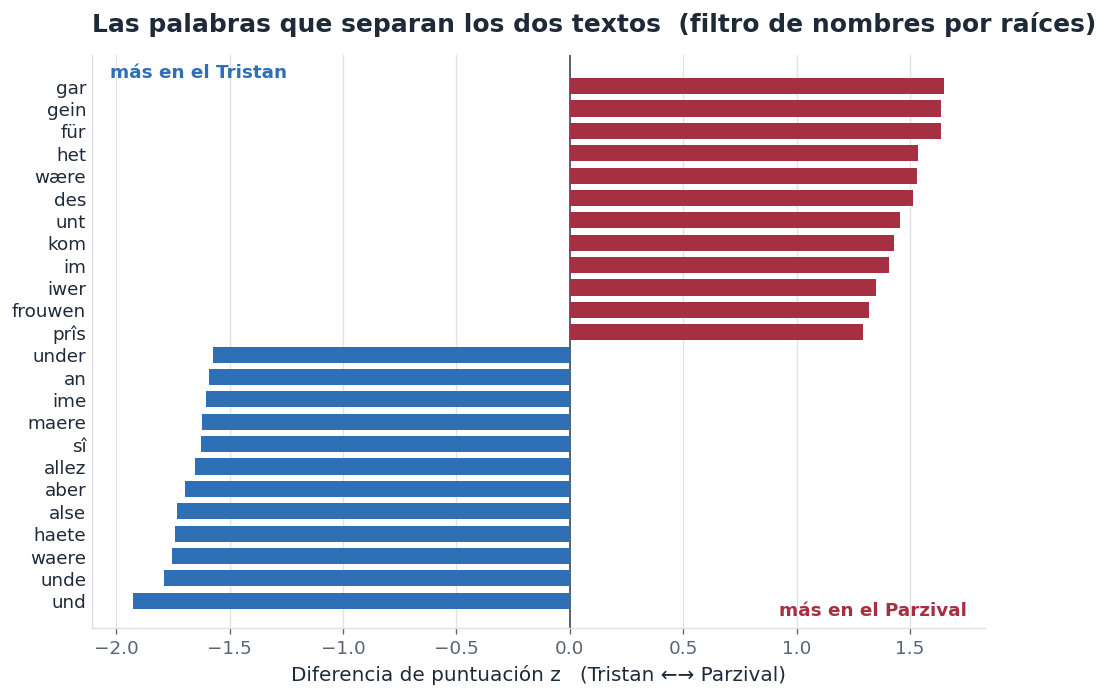


DATO
  52 fragmentos del Parzival y 40 del Tristan, de 2.500 palabras, sobre 150 palabras frecuentes con filtro de nombres por raíces.
  De las 100 palabras más frecuentes de cada obra, 68 son las mismas:
  lo que las distingue no es qué palabras usan, sino en qué proporción.


In [8]:
# ─────────────  6. LO QUE DELTA RESTA  ─────────────
NMFW, VENT = 150, 2500

RAICES_EXCLUIDAS = {sin_diacriticos(v) for obra in RAICES.values() for var in obra.values() for v in var}

def fragmentos(toks, v=VENT):
    return [toks[i:i + v] for i in range(0, len(toks) - v + 1, v)]

FRAG = {o: fragmentos(TOK[o]) for o in TOK}

conjunto = Counter()
for t in TOK.values(): conjunto.update(t)
MFW = [w for w, _ in conjunto.most_common(NMFW + 400)
       if not sin_diacriticos(w).startswith(tuple(RAICES_EXCLUIDAS))][:NMFW]

def perfil(toks):
    c = Counter(toks)
    return np.array([c.get(w, 0) / len(toks) for w in MFW])

X  = np.vstack([perfil(f) for o in FRAG for f in FRAG[o]])
ET = [o for o in FRAG for _ in FRAG[o]]
MU, SD = X.mean(0), X.std(0); SD[SD == 0] = 1
Z = (X - MU) / SD
medio = {o: Z[[i for i, e in enumerate(ET) if e == o]].mean(0) for o in FRAG}

dif = medio['Parzival'] - medio['Tristan']
orden = np.argsort(dif)
sel = np.concatenate([orden[:12], orden[-12:]])
sel = sel[np.argsort(dif[sel])]
fig, ax = plt.subplots(figsize=(9.6, 6.2))
ax.barh(range(len(sel)), dif[sel], height=0.72, zorder=3,
        color=[COLOR['Tristan'] if dif[i] < 0 else COLOR['Parzival'] for i in sel])
ax.set_yticks(range(len(sel))); ax.set_yticklabels([MFW[i] for i in sel], fontsize=11, color=INK)
ax.tick_params(axis='y', length=0)
ax.axvline(0, color=MUTED, lw=1.2)
ax.set_ylim(-1.2, len(sel) + 0.4)
marco(ax, 'Las palabras que separan los dos textos  (filtro de nombres por raíces)',
      'Diferencia de puntuación z   (Tristan ←→ Parzival)', None, rejilla='x')
ax.annotate('más en el Tristan', (0.02, 0.985), xycoords='axes fraction', color=COLOR['Tristan'],
            fontweight='bold', fontsize=11, ha='left', va='top')
ax.annotate('más en el Parzival', (0.98, 0.015), xycoords='axes fraction', color=COLOR['Parzival'],
            fontweight='bold', fontsize=11, ha='right', va='bottom')
guardar(fig, 'fig4_zscores.png'); plt.show()

cien = {o: {w for w, _ in FRQ[o].most_common(100)} for o in TOK}
comunes = cien['Parzival'] & cien['Tristan']
print('\nDATO')
print(f'  {len(FRAG["Parzival"])} fragmentos del Parzival y {len(FRAG["Tristan"])} del Tristan, '
      f'de {mil(VENT)} palabras, sobre {NMFW} palabras frecuentes con filtro de nombres por raíces.')
print(f'  De las 100 palabras más frecuentes de cada obra, {len(comunes)} son las mismas:')
print('  lo que las distingue no es qué palabras usan, sino en qué proporción.')


## 7 · Agrupación exploratoria
Las etiquetas se añaden después del cálculo. Se discrimina entre obras, no se valida autoría fuera de la obra.

→ figuras_braga/fig5a_dendrograma.png


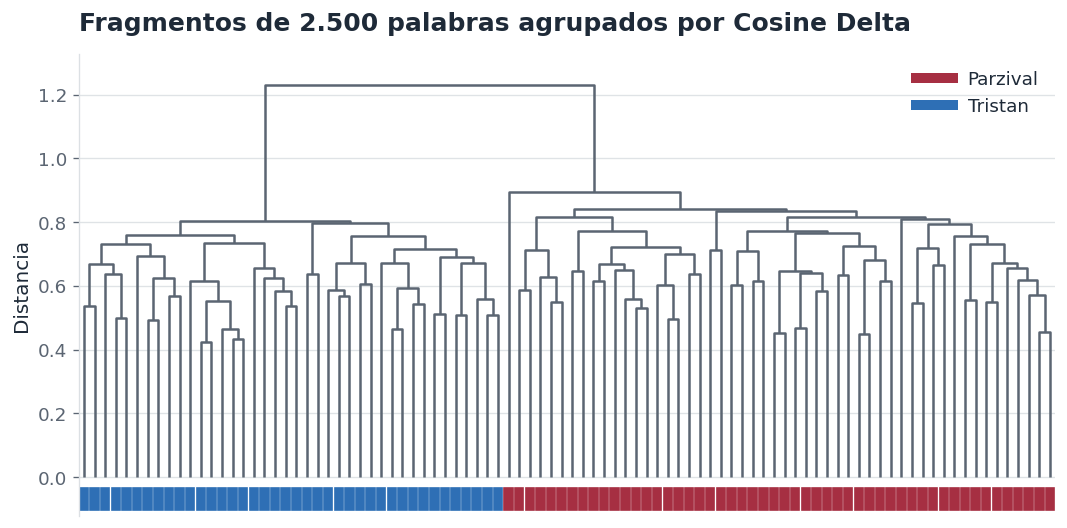

→ figuras_braga/fig5b_pca.png


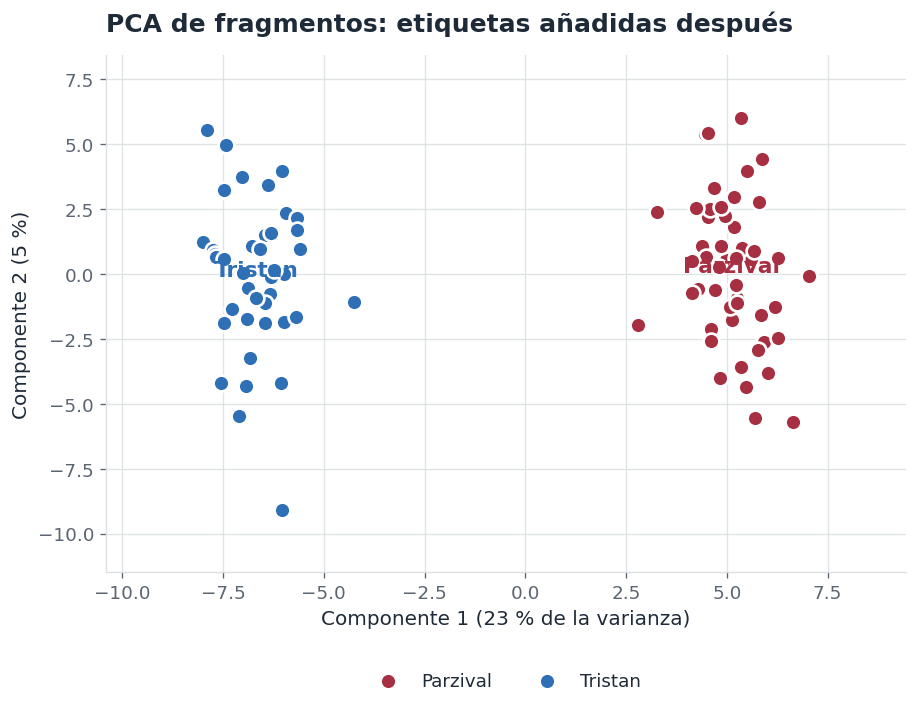


DATO
  Delta medio dentro de la misma obra: 0.927
  Delta medio entre obras distintas:   1.262  (1.4 veces mayor)
  El vecino más próximo de cada fragmento es de su misma obra en el 100% de los casos.


In [9]:
# ─────────────  7. AGRUPACIÓN DE LOS FRAGMENTOS  ─────────────
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
import matplotlib.patches as mpatches

D_burrows = squareform(pdist(Z, metric='cityblock') / Z.shape[1])   # Delta de Burrows
D_cos     = squareform(pdist(Z, metric='cosine'))                   # Cosine Delta
Lk = linkage(squareform(D_cos, checks=False), method='average')

fig, ax = plt.subplots(figsize=(10.5, 5.0))
dn = dendrogram(Lk, no_labels=True, ax=ax, color_threshold=0, above_threshold_color=MUTED)
alto = Lk[-1, 2] * 0.055
for k, hoja in enumerate(dn['leaves']):
    ax.add_patch(mpatches.Rectangle((10 * k + 1, -alto * 1.5), 8, alto,
                                    color=COLOR[ET[hoja]], clip_on=False))
ax.set_ylim(-alto * 1.8, Lk[-1, 2] * 1.08)
ax.spines['bottom'].set_visible(False); ax.set_xticks([])
marco(ax, f'Fragmentos de {mil(VENT)} palabras agrupados por Cosine Delta', None, 'Distancia')
for o, c in COLOR.items(): ax.plot([], [], color=c, lw=6, label=o)
ax.legend(loc='upper right', fontsize=11)
guardar(fig, 'fig5a_dendrograma.png'); plt.show()

Zc = Z - Z.mean(0)
U, S_, _ = np.linalg.svd(Zc, full_matrices=False)
pc = U[:, :2] * S_[:2]
var = (S_ ** 2 / (S_ ** 2).sum())[:2] * 100
fig, ax = plt.subplots(figsize=(8.6, 5.6))
for o in FRAG:
    idx = [i for i, e in enumerate(ET) if e == o]
    ax.scatter(pc[idx, 0], pc[idx, 1], s=90, color=COLOR[o], label=o,
               edgecolor='white', linewidth=1.6, zorder=3)
    ax.annotate(o, (pc[idx, 0].mean(), pc[idx, 1].mean()), color=COLOR[o],
                fontweight='bold', fontsize=13, ha='center')
ax.margins(0.16)
marco(ax, 'PCA de fragmentos: etiquetas añadidas después',
      f'Componente 1 ({var[0]:.0f} % de la varianza)', f'Componente 2 ({var[1]:.0f} %)', rejilla='both')
ax.legend(loc='upper center', ncol=2, fontsize=11, bbox_to_anchor=(0.5, -0.16))
guardar(fig, 'fig5b_pca.png'); plt.show()

ip = [i for i, e in enumerate(ET) if e == 'Parzival']
it = [i for i, e in enumerate(ET) if e == 'Tristan']
dentro = np.mean([D_burrows[np.ix_(ip, ip)][np.triu_indices(len(ip), 1)].mean(),
                  D_burrows[np.ix_(it, it)][np.triu_indices(len(it), 1)].mean()])
entre = D_burrows[np.ix_(ip, it)].mean()
acierto = np.mean([ET[i] == ET[np.argsort(D_cos[i])[1]] for i in range(len(ET))])
print('\nDATO')
print(f'  Delta medio dentro de la misma obra: {dentro:.3f}')
print(f'  Delta medio entre obras distintas:   {entre:.3f}  ({entre/dentro:.1f} veces mayor)')
print(f'  El vecino más próximo de cada fragmento es de su misma obra en el {acierto:.0%} de los casos.')


## 8 · Rolling Delta
MFW, medias, desviaciones y perfiles se construyen solo con segundas mitades; primeras mitades reservadas para la prueba. Una unión artificial no estima precisión general.

→ figuras_braga/fig6_rolling.png


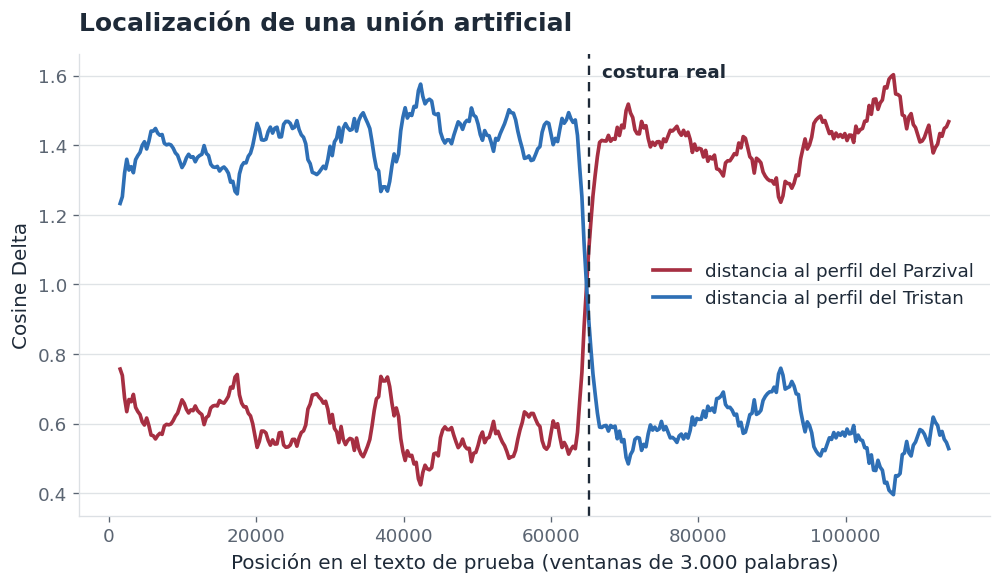


DATO
  Costura real en la palabra 65.165.
  El método la sitúa en 65.100: error de 65 palabras, un 0.1% del texto.
  Acierta la obra en el 100% de las ventanas.


In [10]:
# ─────────────  8. ROLLING DELTA  ─────────────
VENT_R, PASO_R = 3000, 300

mitad = {o: len(TOK[o]) // 2 for o in TOK}
prueba  = TOK['Parzival'][:mitad['Parzival']] + TOK['Tristan'][:mitad['Tristan']]
costura = mitad['Parzival']
referencia={o:TOK[o][mitad[o]:] for o in TOK}
cuenta_ref=Counter(t for ts in referencia.values() for t in ts)
MFW_R=[w for w,_ in cuenta_ref.most_common() if not sin_diacriticos(w).startswith(tuple(RAICES_EXCLUIDAS))][:NMFW]
def perfil_r(toks):
    c=Counter(toks); return np.array([c[w]/len(toks) for w in MFW_R])
XR=np.vstack([perfil_r(f) for o in referencia for f in fragmentos(referencia[o])])
MU_R,SD_R=XR.mean(0),XR.std(0); SD_R[SD_R==0]=1
refs={o:(perfil_r(ts)-MU_R)/SD_R for o,ts in referencia.items()}

xs, curvas = [], {o: [] for o in refs}
for i in range(0, len(prueba) - VENT_R + 1, PASO_R):
    z = (perfil_r(prueba[i:i + VENT_R]) - MU_R) / SD_R
    xs.append(i + VENT_R // 2)
    for o, b in refs.items():
        curvas[o].append(1 - float(z @ b / (np.linalg.norm(z) * np.linalg.norm(b))))

fig, ax = plt.subplots(figsize=(9.8, 5.0))
for o in curvas:
    ax.plot(xs, curvas[o], color=COLOR[o], lw=2.2, label=f'distancia al perfil del {o}')
ax.axvline(costura, color=INK, lw=1.4, ls=(0, (4, 3)))
ax.annotate('costura real', (costura, ax.get_ylim()[1]), xytext=(8, -14), textcoords='offset points',
            color=INK, fontweight='bold', fontsize=11)
marco(ax, 'Localización de una unión artificial',
      f'Posición en el texto de prueba (ventanas de {mil(VENT_R)} palabras)', 'Cosine Delta')
ax.legend(loc='center right', fontsize=11)
guardar(fig, 'fig6_rolling.png'); plt.show()

gana = [min(curvas, key=lambda o: curvas[o][i]) for i in range(len(xs))]
saltos = [xs[i] for i in range(1, len(gana)) if gana[i] != gana[i - 1]]
print('\nDATO')
print(f'  Costura real en la palabra {mil(costura)}.')
if saltos:
    e = abs(saltos[0] - costura)
    print(f'  El método la sitúa en {mil(saltos[0])}: error de {mil(e)} palabras, '
          f'un {e/len(prueba):.1%} del texto.')
else:
    print('  El método no detecta ningún cambio.')
cierto = np.mean([g == ('Parzival' if x < costura else 'Tristan') for g, x in zip(gana, xs)])
print(f'  Acierta la obra en el {cierto:.0%} de las ventanas.')


## 9 · Menciones de personajes
Búsqueda por raíces, no NER ni resolución de entidades; posibles falsos positivos y negativos.

→ figuras_braga/fig7_personajes_parzival.png


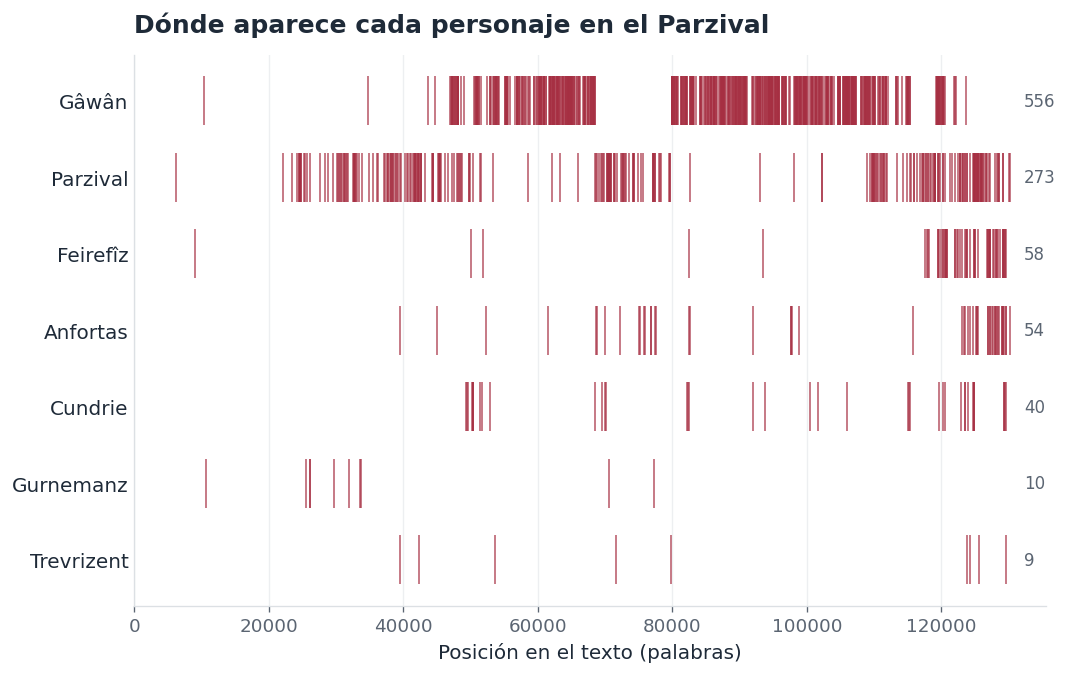

  Parzival: Gâwân 556 · Parzival 273 · Feirefîz 58 · Anfortas 54 · Cundrie 40 · Gurnemanz 10 · Trevrizent 9



→ figuras_braga/fig7_personajes_tristan.png


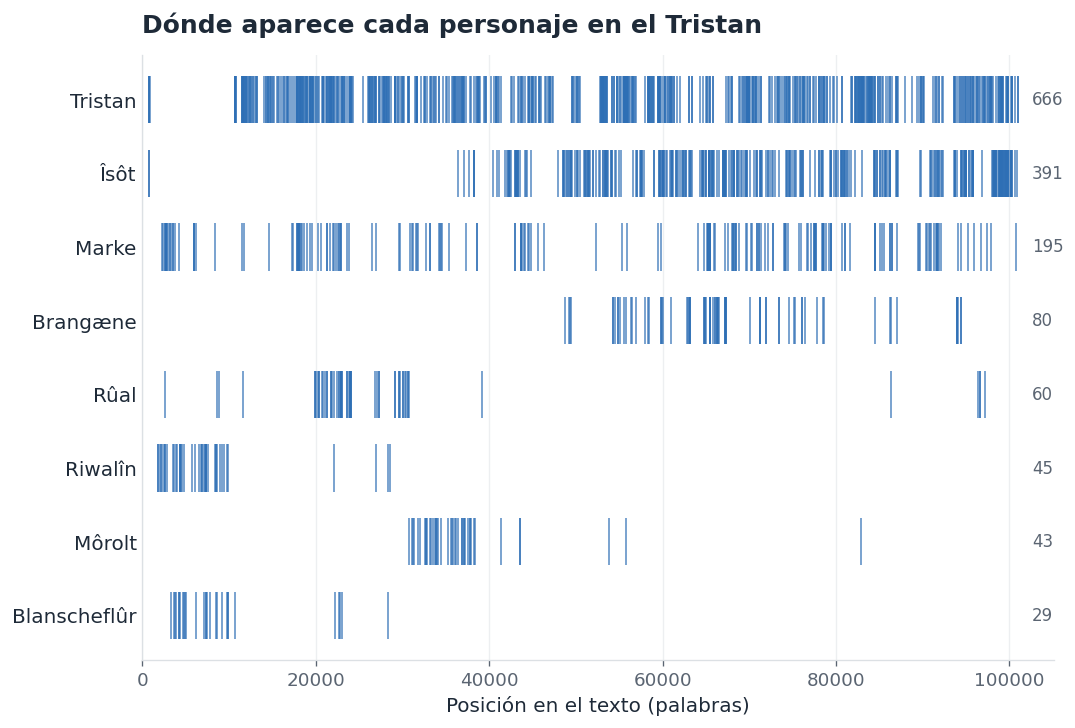

  Tristan: Tristan 666 · Îsôt 391 · Marke 195 · Brangæne 80 · Rûal 60 · Riwalîn 45 · Môrolt 43 · Blanscheflûr 29



In [11]:
# ─────────────  9. DISPERSIÓN DE PERSONAJES  ─────────────
for obra, pers in RAICES.items():
    toks = TOK[obra]; N = len(toks)
    plano = [sin_diacriticos(t) for t in toks]
    filas = []
    for nombre, raices in pers.items():
        rs = tuple(sin_diacriticos(r) for r in raices)
        pos = [i for i, t in enumerate(plano) if t.startswith(rs)]
        if pos: filas.append((nombre, pos))
    filas.sort(key=lambda f: -len(f[1]))

    fig, ax = plt.subplots(figsize=(9.8, 0.58 * len(filas) + 1.9))
    for j, (nombre, pos) in enumerate(filas):
        y = len(filas) - 1 - j
        ax.vlines(pos, y - 0.32, y + 0.32, color=COLOR[obra], lw=1.0, alpha=0.75)
        ax.annotate(f'{len(pos)}', (N, y), xytext=(8, 0), textcoords='offset points',
                    va='center', color=MUTED, fontsize=10)
    ax.set_yticks(range(len(filas))); ax.set_yticklabels([f[0] for f in filas][::-1], fontsize=12, color=INK)
    ax.set_xlim(0, N * 1.04); ax.set_ylim(-0.6, len(filas) - 0.4)
    ax.tick_params(axis='y', length=0)
    marco(ax, f'Dónde aparece cada personaje en el {obra}', 'Posición en el texto (palabras)', None, rejilla='x')
    ax.grid(axis='x', alpha=0.5)
    guardar(fig, f'fig7_personajes_{obra.lower()}.png'); plt.show()
    print('  ' + obra + ': ' + ' · '.join(f'{n} {len(p)}' for n, p in filas) + '\n')


## 10 · La ley de Heaps

El vocabulario crece con el texto, pero cada vez más despacio: como una raíz, no como una recta.
Por eso un corpus mayor nunca agota la lengua y siempre aparecen formas nuevas, y por eso la cifra
de *hapax* se mantiene alta por mucho que se amplíe el corpus.


  Parzival: V ≈ 8.9 · N^0.61
  Tristan: V ≈ 6.2 · N^0.62


→ figuras_braga/fig8_heaps.png


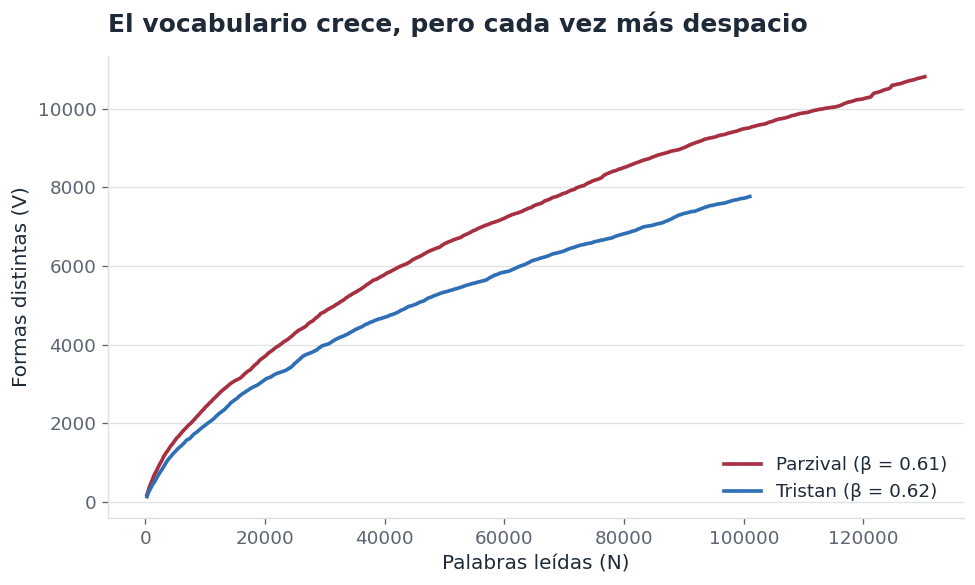

In [12]:
# ─────────────  10. LEY DE HEAPS  ─────────────
fig, ax = plt.subplots(figsize=(9.2, 5.0))
for obra in TOK:
    vistos, xs, ys = set(), [], []
    for i, t in enumerate(TOK[obra], 1):
        vistos.add(t)
        if i % 250 == 0: xs.append(i); ys.append(len(vistos))
    xs, ys = np.array(xs), np.array(ys)
    b, loga = np.polyfit(np.log(xs), np.log(ys), 1)
    ax.plot(xs, ys, color=COLOR[obra], lw=2.2, label=f'{obra} (β = {b:.2f})')
    print(f'  {obra}: V ≈ {math.exp(loga):.1f} · N^{b:.2f}')
marco(ax, 'El vocabulario crece, pero cada vez más despacio',
      'Palabras leídas (N)', 'Formas distintas (V)')
ax.legend(loc='lower right', fontsize=11)
guardar(fig, 'fig8_heaps.png'); plt.show()


## 11 · Resumen de datos


In [13]:
# ─────────────  11. RESUMEN  ─────────────
raya = '─' * 62
print(raya)
for obra in TOK:
    h, r = hapax[obra], riqueza[obra]
    print(obra)
    print(f'  {mil(r["n"])} palabras · {mil(len(FRQ[obra]))} formas distintas')
    print(f'  TTR {r["ttr"]:.3f} · STTR(1.000) {r["sttr"]:.3f} · MTLD {r["mtld"]:.0f}')
    print(f'  hapax {mil(h["n"])} = {h["pct"]:.0f} % de las formas')
    print(f'  pendiente de Zipf α = {zipf[obra]:.2f}')
    print(f'  longitud media de palabra {longitud[obra]["media"]:.2f} caracteres')
    print('  diez más frecuentes: ' + ' · '.join(w for w, _ in FRQ[obra].most_common(10)))
    print(raya)
print(f'Fragmentos de {mil(VENT)} palabras · {NMFW} palabras frecuentes con filtro de nombres por raíces')
print(f'  Delta dentro de la obra {dentro:.3f} · entre obras {entre:.3f} ({entre/dentro:.1f}×)')
print(f'  Vecino más próximo de la misma obra: {acierto:.0%}')
print(f'  Las 100 palabras más frecuentes de cada obra comparten {len(comunes)}')
print(raya)
print(f'Figuras guardadas en {SALIDA}/')


──────────────────────────────────────────────────────────────
Parzival
  130.330 palabras · 10.815 formas distintas
  TTR 0.083 · STTR(1.000) 0.501 · MTLD 193
  hapax 5.228 = 48 % de las formas
  pendiente de Zipf α = 1.04
  longitud media de palabra 4.28 caracteres
  diez más frecuentes: der · daz · ir · er · ich · in · si · von · den · die
──────────────────────────────────────────────────────────────
Tristan
  101.082 palabras · 7.772 formas distintas
  TTR 0.077 · STTR(1.000) 0.428 · MTLD 106
  hapax 3.741 = 48 % de las formas
  pendiente de Zipf α = 1.14
  longitud media de palabra 4.21 caracteres
  diez más frecuentes: und · daz · ir · der · er · in · an · unde · ich · diu
──────────────────────────────────────────────────────────────
Fragmentos de 2.500 palabras · 150 palabras frecuentes con filtro de nombres por raíces
  Delta dentro de la obra 0.927 · entre obras 1.262 (1.4×)
  Vecino más próximo de la misma obra: 100%
  Las 100 palabras más frecuentes de cada obra comparten 

## 12 · Longitud y afijos
Patrones heurísticos; longitud no equivale a composición.

Parzival: 345 nombres propios apartados  (gâwân, parzivâl, artûs, anschevîn, gramoflanz, gahmuretes…)
Tristan: 111 nombres propios apartados  (tristan, îsôt, marke, îsôte, tristande, tristanden…)

Parzival
   formas de 10 caracteres o más: 1.146 (10.6 % del vocabulario)
   de ellas son hapax: 74 %   (en el vocabulario entero: 48 %)
   la más larga: schâchzabelgesteine (19 caracteres)
   las largas más frecuentes: sicherheit (56), rîterschaft (53), tavelrunder (44), herzoginne (43), geselleschaft (36), juncfrouwen (33), juncfrouwe (23), ritterschaft (20)

Tristan
   formas de 10 caracteres o más: 1.108 (14.3 % del vocabulario)
   de ellas son hapax: 71 %   (en el vocabulario entero: 48 %)
   la más larga: unversprochenlîche (18 caracteres)
   las largas más frecuentes: ritterschaft (40), inneclîche (31), iegelîcher (18), geselleschaft (17), iegelîchem (16), tougenlîche (15), künicrîche (14), bescheiden (14)



→ figuras_braga/fig12_compuestos.png


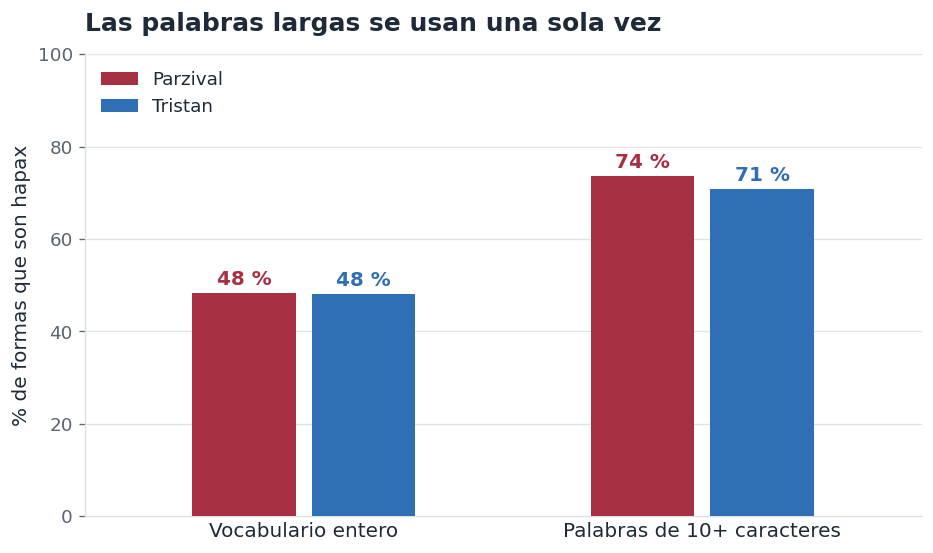

Formas distintas que llevan cada afijo

                        PREFIJOS                   SUFIJOS
             Parzival    Tristan         Parzival    Tristan
ge-               686        715      -lîch             353        361
ver-              273        209      -clîch             92         81
un-               262        206      -ære               53         80
be-               222        264      -lîn               49         67
er-               217        158      -heit              46         54
ent-               49         49      -unge              36         30
über-              34         26      -inne              32         42
wider-             26         25      -bære              23         41
zer-               18          6      -schaft            19         16
durch-             10          7      -tuom              10          3
misse-             10         29      -sam                2         19

Avisos: «ge-» incluye los participios, que son morfología 

→ figuras_braga/fig13_sufijos.png


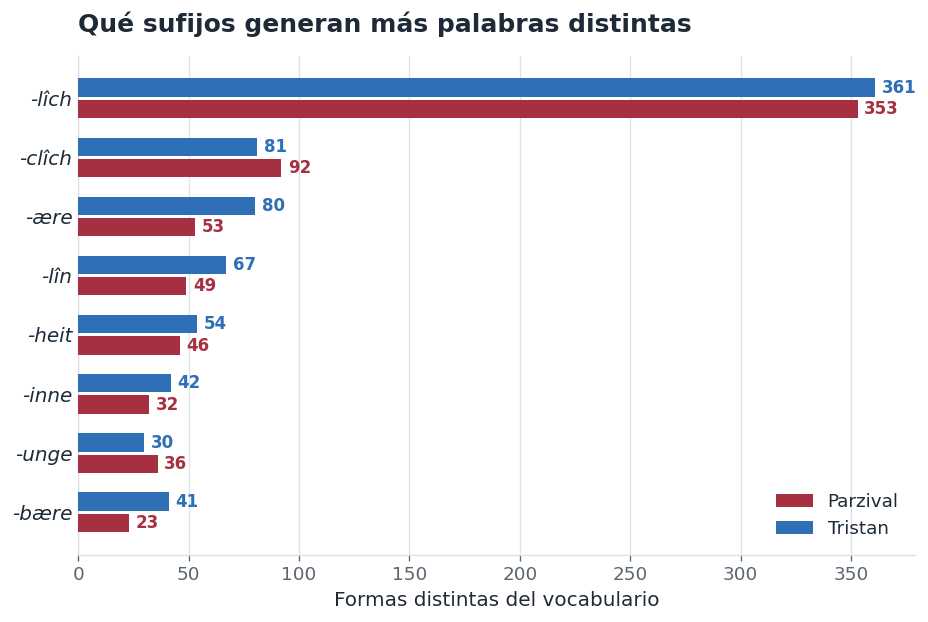


DATO
  Parzival: 1.146 formas de 10+ caracteres, el 10.6 % del vocabulario; 74 % de ellas aparecen una sola vez, frente al 48 % del vocabulario entero.
  Tristan: 1.108 formas de 10+ caracteres, el 14.3 % del vocabulario; 71 % de ellas aparecen una sola vez, frente al 48 % del vocabulario entero.
  La longitud es un indicador indirecto, no demuestra composición ni acuñación.


In [14]:
# ═══════════  12 · MORFOLOGÍA DERIVATIVA: DÓNDE ESTÁ LA DIFICULTAD  ═══════════
#
# Los apartados anteriores cuentan formas gráficas y dan por supuesto que cada
# forma es una palabra. En alemán ese supuesto es más frágil que en español o en
# portugués, porque la lengua compone y deriva sin límite: una sola forma gráfica
# puede ser lo que en otra lengua son tres o cuatro palabras.
#
# Este apartado mide ese fenómeno en las dos obras. No detecta compuestos —eso
# exigiría un lexicón morfológico del MHD que no existe en abierto—, sino que
# usa dos indicadores que sí son reproducibles: la longitud de la palabra, que
# en alemán es un buen indicio de complejidad morfológica, y la productividad de
# los prefijos y sufijos derivativos, que se reconocen por el extremo de la
# palabra con patrones anclados.
#
# Necesita el apartado 0 (TOK, FRQ, RUTAS, LETRAS, COLOR, INK, marco, guardar, mil).

import os
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

_faltan = [n for n in ('TOK', 'FRQ', 'RUTAS', 'LETRAS', 'COLOR', 'INK',
                       'marco', 'guardar', 'mil') if n not in globals()]
if _faltan:
    raise NameError('Ejecuta primero el apartado 0. Faltan: ' + ', '.join(_faltan))

UMBRAL = 10        # caracteres a partir de los cuales una palabra es "larga"
MINIMO_AFIJO = 6   # longitud mínima para buscar prefijo o sufijo


# ─────────────────────────────────────────────────────────────────────────────
# 1 · Nombres propios: hay que apartarlos
#
# Las formas flexionadas de los nombres (Tristande, Tristanden, Gahmuretes)
# son largas, pero no son compuestos: son un nombre en genitivo o dativo. Sin
# este filtro encabezan la lista de palabras largas y la falsean entera.
#
# En vez de una lista escrita a mano, se deducen del propio texto: una palabra
# que aparece con mayúscula en el interior de un verso —no al principio— es,
# casi siempre, un nombre propio.
# ─────────────────────────────────────────────────────────────────────────────
RE_PALABRA_CRUDA = re.compile(f"[{LETRAS}]+", re.IGNORECASE)
RE_BASURA = re.compile(r'<<<|>>>|^\s*_+\s*$')

NOMBRES = {}
for obra, ruta in RUTAS.items():
    cuenta = Counter()
    with open(ruta, encoding='utf-8', errors='replace') as f:
        for linea in f:
            if RE_BASURA.search(linea):
                continue
            palabras = RE_PALABRA_CRUDA.findall(unicodedata.normalize('NFC', linea))
            for p in palabras[1:]:          # el primero abre verso: su mayúscula no dice nada
                if p[:1].isupper():
                    cuenta[p.lower()] += 1
    NOMBRES[obra] = {p for p, n in cuenta.items() if n >= 2}
    muestra = ', '.join(p for p, _ in cuenta.most_common(6))
    print(f'{obra}: {mil(len(NOMBRES[obra]))} nombres propios apartados  ({muestra}…)')


# ─────────────────────────────────────────────────────────────────────────────
# 2 · Palabras largas: el indicio de composición
# ─────────────────────────────────────────────────────────────────────────────
print()
LARGAS, RES = {}, {}
for obra in TOK:
    frq = FRQ[obra]
    largas = {p: n for p, n in frq.items()
              if len(p) >= UMBRAL and p not in NOMBRES[obra]}
    LARGAS[obra] = largas

    hapax_total = sum(1 for n in frq.values() if n == 1)
    hapax_largas = sum(1 for n in largas.values() if n == 1)
    RES[obra] = {
        'formas': len(frq),
        'largas': len(largas),
        'pct_largas': 100 * len(largas) / len(frq),
        'hapax_pct': 100 * hapax_total / len(frq),
        'hapax_largas_pct': 100 * hapax_largas / len(largas),
        'mas_larga': max(largas, key=len),
    }
    d = RES[obra]
    print(f'{obra}')
    print(f'   formas de {UMBRAL} caracteres o más: {mil(d["largas"])} '
          f'({d["pct_largas"]:.1f} % del vocabulario)')
    print(f'   de ellas son hapax: {d["hapax_largas_pct"]:.0f} %   '
          f'(en el vocabulario entero: {d["hapax_pct"]:.0f} %)')
    print(f'   la más larga: {d["mas_larga"]} ({len(d["mas_larga"])} caracteres)')
    frecuentes = sorted(largas.items(), key=lambda kv: -kv[1])[:8]
    print('   las largas más frecuentes: '
          + ', '.join(f'{p} ({n})' for p, n in frecuentes))
    print()


# ── Figura 12 · hapax entre las palabras largas frente al vocabulario entero ──
fig, ax = plt.subplots(figsize=(9.0, 5.0))
ancho = 0.3
etiquetas = ['Vocabulario entero', f'Palabras de {UMBRAL}+ caracteres']
for i, obra in enumerate(RES):
    alturas = [RES[obra]['hapax_pct'], RES[obra]['hapax_largas_pct']]
    pos = np.arange(2) + (i - 0.5) * ancho
    ax.bar(pos, alturas, width=ancho - 0.04, color=COLOR[obra], label=obra, zorder=3)
    for x, h in zip(pos, alturas):
        ax.annotate(f'{h:.0f} %', (x, h), xytext=(0, 5), textcoords='offset points',
                    ha='center', color=COLOR[obra], fontweight='bold', fontsize=12)
ax.set_xticks(range(2))
ax.set_xticklabels(etiquetas, fontsize=12, color=INK)
ax.set_xlim(-0.55, 1.55)
ax.set_ylim(0, 100)
ax.tick_params(axis='x', length=0)
marco(ax, 'Las palabras largas se usan una sola vez', y='% de formas que son hapax')
ax.legend(loc='upper left', fontsize=11)
guardar(fig, 'fig12_compuestos.png')
plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# 3 · Prefijos y sufijos derivativos
#
# Se cuentan formas distintas del vocabulario, no apariciones: lo que interesa
# es cuántas palabras *diferentes* genera cada afijo, que es la medida de su
# productividad. Los patrones van anclados y exigen una raíz mínima, para no
# capturar palabras que simplemente empiezan por esas letras.
# ─────────────────────────────────────────────────────────────────────────────
PREFIJOS = {
    'un-':     r'^un.{4,}',       # negación: unmâze, untriuwe, ungemüete
    'ge-':     r'^ge.{5,}',       # colectivo y perfectivo (incluye participios)
    'be-':     r'^be.{5,}',
    'er-':     r'^er.{5,}',       # completivo: erkennen, erleben
    'ver-':    r'^ver.{4,}',      # transformativo: verligen, verderben
    'zer-':    r'^zer.{4,}',      # destructivo: zerbrechen
    'ent-':    r'^ent.{4,}',      # separación: entgân
    'wider-':  r'^wider.{3,}',
    'über-':   r'^über.{3,}|^uber.{3,}',
    'durch-':  r'^durch.{3,}',
    'misse-':  r'^misse.{3,}',    # error: missevarn
}

SUFIJOS = {
    # Los patrones admiten la terminación de flexión (-e, -en, -er, -es, -em),
    # porque en MHD el sufijo casi nunca queda en posición final absoluta:
    # «inneclîche» lleva -clîch igual que «inneclîch».
    '-heit':   r'heit(e|en)?$',            # abstracto: saelekeit, wârheit
    '-schaft': r'schaft(e|en)?$',          # colectivo: ritterschaft, geselleschaft
    '-unge':   r'unge(n)?$',               # nominalización verbal
    '-lîch':   r'l[iî]ch(e|er|es|em|en|et)?$',   # adjetivo de cualidad
    '-clîch':  r'cl[iî]ch(e|er|es|em|en)?$',     # variante MHD: minneclîche
    '-bære':   r'b(ære|aere|ere)(n|r|s|m)?$',    # capacidad: minnebære
    '-sam':    r'sam(e|en|er|es)?$',
    '-inne':   r'inne(n)?$',               # agente femenino: küneginne
    '-nisse':  r'n[iü]sse(n)?$',
    '-tuom':   r'tuom(e|es|en)?$',
    '-ære':    r'(?<!b)(ære|aere)(n|s|m)?$',     # agente: senedære, trûraere
    '-lîn':    r'l[iî]n(e|es|en)?$',       # diminutivo: herzelîn, hundelîn
}


def productividad(vocabulario, patrones, longitud_minima):
    base = [p for p in vocabulario if len(p) >= longitud_minima]
    return {nombre: sum(1 for p in base if re.search(pat, p))
            for nombre, pat in patrones.items()}


PREF, SUF = {}, {}
for obra in TOK:
    vocab = [p for p in FRQ[obra] if p not in NOMBRES[obra]]
    PREF[obra] = productividad(vocab, PREFIJOS, MINIMO_AFIJO)
    SUF[obra] = productividad(vocab, SUFIJOS, 5)

print('Formas distintas que llevan cada afijo\n')
print(f'{"":10}{"PREFIJOS":>22}{"":6}{"SUFIJOS":>20}')
obras = list(TOK)
print(f'{"":10}' + ''.join(f'{o:>11}' for o in obras)
      + f'{"":6}' + ''.join(f'{o:>11}' for o in obras))
for pre, suf in zip(sorted(PREFIJOS, key=lambda k: -PREF[obras[0]][k]),
                    sorted(SUFIJOS, key=lambda k: -SUF[obras[0]][k])):
    fila = f'{pre:<10}' + ''.join(f'{mil(PREF[o][pre]):>11}' for o in obras)
    fila += f'{"":6}{suf:<10}' + ''.join(f'{mil(SUF[o][suf]):>11}' for o in obras)
    print(fila)
print('\nAvisos: «ge-» incluye los participios, que son morfología flexiva y no')
print('derivativa; su cifra es una cota superior. Y «-clîch» está contenido en')
print('«-lîch»: las dos filas no se suman.')


# ── Figura 13 · los sufijos más productivos ──
orden = sorted(SUFIJOS, key=lambda k: -sum(SUF[o][k] for o in obras))[:8]
fig, ax = plt.subplots(figsize=(9.0, 5.4))
alto = 0.36
y = np.arange(len(orden))
for i, obra in enumerate(obras):
    valores = [SUF[obra][s] for s in orden]
    ax.barh(y + (0.5 - i) * alto, valores, height=alto - 0.05,
            color=COLOR[obra], label=obra, zorder=3)
    for v, yy in zip(valores, y + (0.5 - i) * alto):
        ax.annotate(mil(v), (v, yy), xytext=(4, 0), textcoords='offset points',
                    va='center', color=COLOR[obra], fontweight='bold', fontsize=10)
ax.set_yticks(y)
ax.set_yticklabels(orden, fontsize=12, color=INK, fontstyle='italic')
ax.invert_yaxis()
ax.tick_params(axis='y', length=0)
marco(ax, 'Qué sufijos generan más palabras distintas',
      x='Formas distintas del vocabulario', rejilla='x')
ax.legend(loc='lower right', fontsize=11)
guardar(fig, 'fig13_sufijos.png')
plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# 4 · El dato
# ─────────────────────────────────────────────────────────────────────────────
print('\nDATO')
for obra in obras:
    d = RES[obra]
    print(f'  {obra}: {mil(d["largas"])} formas de {UMBRAL}+ caracteres, '
          f'el {d["pct_largas"]:.1f} % del vocabulario; '
          f'{d["hapax_largas_pct"]:.0f} % de ellas aparecen una sola vez, '
          f'frente al {d["hapax_pct"]:.0f} % del vocabulario entero.')
print('  La longitud es un indicador indirecto, no demuestra composición ni acuñación.')


## 13 · Formas seleccionadas del léxico cortés
Recuento exploratorio, no lemas completos ni conceptos. Se excluyen formas ambiguas como minnen, êren y mâzen y derivados; se incluyen variantes gráficas seleccionadas. Se exportan concordancias con línea del archivo, no numeración canónica. No se generaliza a los autores.

Parzival minne 355 27.24
Parzival triuwe 140 10.74
Parzival êre 77 5.91
Parzival jâmer 132 10.13
Parzival mâze 20 1.53
Tristan minne 160 15.83
Tristan triuwe 67 6.63
Tristan êre 158 15.63
Tristan jâmer 28 2.77
Tristan mâze 34 3.36
→ figuras_braga/fig14_lexico.png


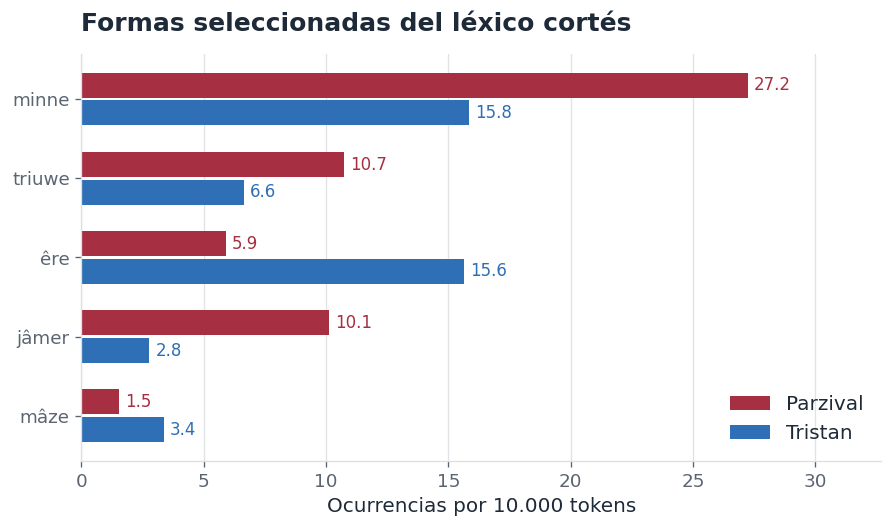

In [15]:
import csv
FORMAS={'minne':{'minne'},'triuwe':{'triwe','triuwe'},'êre':{'êre'},'jâmer':{'jâmer','jâmor','jâmers','jamers'},'mâze':{'mâze'}}
lex_rows=[];kwic=[]
for obra,toks in TOK.items():
    lista=[(t,i) for i,l in enumerate(Path(RUTAS[obra]).read_text().splitlines(),1) for t in tokenizar(l)]
    assert [t for t,_ in lista]==toks
    for g,formas in FORMAS.items():
        n=sum(FRQ[obra][w] for w in formas); tasa=n/len(toks)*10000
        lex_rows.append(dict(obra=obra,grupo=g,formas='|'.join(sorted(formas)),n=n,por_10000=tasa))
        for i,(t,lin) in enumerate(lista):
            if t in formas: kwic.append(dict(obra=obra,grupo=g,linea_archivo=lin,izquierda=' '.join(toks[max(0,i-8):i]),forma=t,derecha=' '.join(toks[i+1:i+9])))
for fn,rows in [('lexico_cortes.csv',lex_rows),('concordancias_corteses.csv',kwic)]:
    with open(fn,'w',encoding='utf-8-sig',newline='') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
for r in lex_rows: print(r['obra'],r['grupo'],r['n'],round(r['por_10000'],2))
fig,ax=plt.subplots(figsize=(8.6,4.4));y=np.arange(len(FORMAS));h=.35
for i,o in enumerate(TOK):
    vals=[r['por_10000'] for r in lex_rows if r['obra']==o]
    ax.barh(y+(i-.5)*h,vals,height=h-.035,color=COLOR[o],label=o)
    for yy,v in zip(y+(i-.5)*h,vals):ax.text(v+.25,yy,f'{v:.1f}',va='center',fontsize=10,color=COLOR[o])
ax.set_yticks(y,list(FORMAS));ax.invert_yaxis();ax.set_xlim(0,max(r['por_10000'] for r in lex_rows)*1.2)
marco(ax,'Formas seleccionadas del léxico cortés','Ocurrencias por 10.000 tokens',rejilla='x');ax.legend(loc='lower right');guardar(fig,'fig14_lexico.png');plt.show()


### 13.1 · Distribución y coapariciones locales
Décimas de igual número de tokens; tasa por 10.000. Colocados de las formas seleccionadas en ±5 tokens, sin distinguir oración; se cuenta cada par de posiciones (puede haber ventanas solapadas). Se excluyen las 50 formas más frecuentes del corpus y las propias formas del grupo. Se informa frecuencia observada, no asociación semántica, ni significación estadística. Las concordancias conservan las referencias a las líneas del archivo.

→ figuras_braga/fig15_tendencias.png


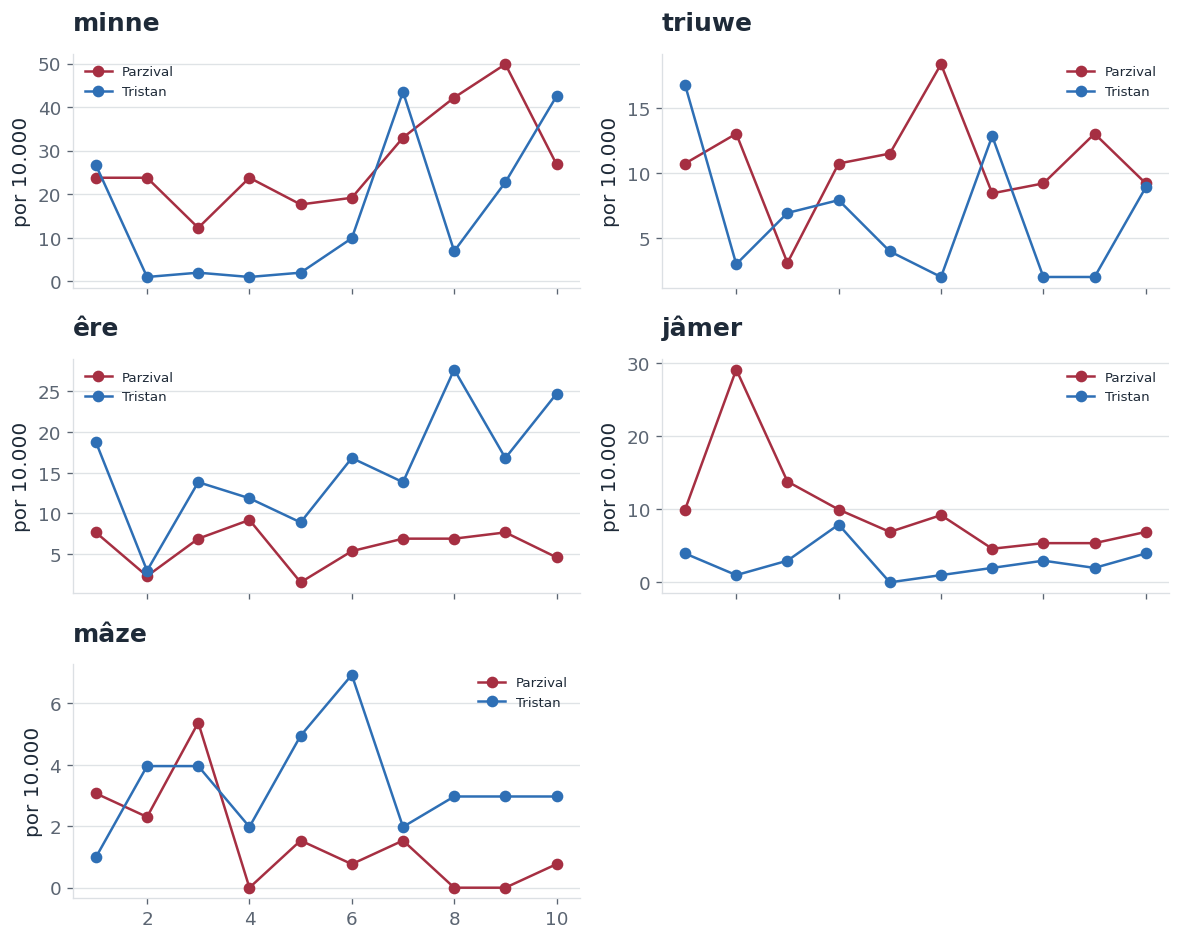

minne P/T = 1.72
triuwe P/T = 1.62
êre P/T = 0.38
jâmer P/T = 3.66
mâze P/T = 0.46


In [16]:
from collections import defaultdict
stop50=set(w for w,_ in (FRQ['Parzival']+FRQ['Tristan']).most_common(50))
trend=[]; coll=[]
fig,axs=plt.subplots(3,2,figsize=(10,8),sharex=True);axs=axs.ravel()
for j,(g,formas) in enumerate(FORMAS.items()):
    for o,t in TOK.items():
        limites=[k*len(t)//10 for k in range(11)]
        vals=[]; colect=Counter()
        for k,(lo,hi) in enumerate(zip(limites,limites[1:]),1):
            cnt=sum(w in formas for w in t[lo:hi]);f=10000*cnt/(hi-lo)
            trend.append(dict(obra=o,grupo=g,decima=k,n=cnt,por_10000=f));vals.append(f)
        axs[j].plot(range(1,11),vals,marker='o',color=COLOR[o],label=o)
        for i,w in enumerate(t):
            if w in formas:
                colect.update(v for v in t[max(i-5,0):i]+t[i+1:i+6] if v not in stop50 and v not in formas)
        for w,c in colect.most_common(30):coll.append(dict(obra=o,grupo=g,forma=w,coapariciones=c))
    marco(axs[j],g,y='por 10.000');axs[j].legend(fontsize=8)
axs[-1].axis('off');fig.tight_layout();guardar(fig,'fig15_tendencias.png');plt.show()
for fn,rows in [('tendencias_corteses.csv',trend),('colocados_corteses.csv',coll)]:
    with open(fn,'w',encoding='utf-8-sig',newline='') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
# Léxico importable en Mâze, pestaña Léxicos.
Path('lexico_cortes_maze.tsv').write_text(''.join(g+'\t'+'\t'.join(sorted(fs))+'\n' for g,fs in FORMAS.items()),encoding='utf-8')
# Cociente de tasas, no contraste de significación; P/T.
for g in FORMAS:
    a,b=[r for r in lex_rows if r['grupo']==g]
    print(g, 'P/T =', round(a['por_10000']/b['por_10000'],2))


## 14 · Sensibilidad y contraste con Mâze
Para comparar con Mâze: alto alemán medio, verso, forma, minúsculas, números no, apóstrofo y guion interno no, ſ→s, diacríticos conservados, sin reglas, MSTTR 1.000. Se incluye el recuento sin umbral, pues Mâze conserva formas de un carácter. Zipf no es directamente comparable: Mâze usa muestreo logarítmico, Python rangos 10–1.000.

In [17]:
sens={}
for o,r in RUTAS.items():
    t=tokenizar(Path(r).read_text(),minimo=1);c=Counter(t)
    sens[o]=dict(N=len(t),V=len(c),V1=sum(v==1 for v in c.values()),ttr=len(c)/len(t),msttr=sttr(t),mtld=mtld(t))
    print(o,sens[o]);print('formas de un carácter:',{w:n for w,n in c.most_common() if len(w)==1})
import json,scipy
resultados={'principal':{o:{**riqueza[o],'V':len(FRQ[o]),'hapax':hapax[o]['n'],'zipf':zipf[o],'largas':RES[o],'top20':FRQ[o].most_common(20)} for o in TOK},'sensibilidad':sens,'delta':dict(dentro=float(dentro),entre=float(entre),vecino=float(acierto),n=len(ET)),'rolling':dict(costura=costura,saltos=saltos,paso=PASO_R,ventana=VENT_R,acierto=float(cierto)),'lexico':lex_rows,'versiones':dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__)}
Path('resultados_braga.json').write_text(json.dumps(resultados,ensure_ascii=False,indent=2,default=lambda x:x.item()),encoding='utf-8')


Parzival {'N': 130724, 'V': 10828, 'V1': 5231, 'ttr': 0.08283100272329488, 'msttr': 0.5021230769230769, 'mtld': 194.8398918892402}
formas de un carácter: {'ê': 224, 'i': 49, 'd': 35, 'n': 24, 'z': 23, 'u': 14, 'r': 11, 's': 5, 'e': 3, 'm': 3, 'â': 1, 'b': 1, 'c': 1}
Tristan {'N': 102115, 'V': 7787, 'V1': 3745, 'ttr': 0.07625716104392107, 'msttr': 0.4285294117647058, 'mtld': 107.59605288168046}
formas de un carácter: {'z': 398, 's': 340, 'ê': 137, 'â': 50, 'n': 50, 'g': 25, 'm': 16, 'r': 6, 'a': 3, 'î': 2, 'l': 2, 'ô': 1, 'd': 1, 't': 1, 'i': 1}


5337

### Contraste independiente de implementación: Mâze 2.0.0
Se ejecutó directamente `analyzeDoc` del núcleo JavaScript del HTML entregado en Node.js, con los TXT depurados y los parámetros anteriores; no una simulación en Python. El navegador de este entorno bloqueó la navegación local, por lo que no se comprobó la interfaz completa. `validar_maze.js` reproduce el contraste si Node.js y `Maze_2.0.0.html` están disponibles; `validacion_maze.json` guarda la salida observada. N, V, V1, TTR, MSTTR(1000), MTLD y las nueve formas corteses seleccionadas coinciden (tolerancia numérica 1e-10); los exponentes de Zipf difieren por el intervalo de ajuste.

In [18]:
# Contraste con el resultado JavaScript incluido en el paquete, si está disponible.
if Path('validacion_maze.json').exists():
    ma=json.loads(Path('validacion_maze.json').read_text())
    for r in ma:
        o=r['name'].capitalize()
        for k,v in sens[o].items(): assert math.isclose(v,r[k],rel_tol=1e-10,abs_tol=1e-10),(o,k,v,r[k])
        for w,v in r['forms'].items(): assert FRQ[o][w]==v,(o,w)
        print(o, 'coinciden N, V, V1, TTR, STTR/MSTTR, MTLD y las formas seleccionadas; Zipf Mâze:',round(r['zipf'],3))
else: print('Sin JSON de contraste. Puede regenerarse con node validar_maze.js.')


Parzival coinciden N, V, V1, TTR, STTR/MSTTR, MTLD y las formas seleccionadas; Zipf Mâze: 1.07
Tristan coinciden N, V, V1, TTR, STTR/MSTTR, MTLD y las formas seleccionadas; Zipf Mâze: 1.118


## 15 · MHGTagger (opcional)
Requiere modelo y dependencias externas compatibles. No se ejecuta por defecto. Las cifras previas se conservan como registro histórico, no resultado del corpus depurado.

In [19]:
EJECUTAR_MHG=False
if EJECUTAR_MHG:
    # ═══════════  15 · DE LA FORMA GRÁFICA AL LEMA CON MHGTagger  ═══════════
    #
    # MHGTagger —el etiquetador de alto alemán medio de Helmut Schmid (CIS, Universidad
    # de Múnich), entrenado sobre el Referenzkorpus Mittelhochdeutsch— devuelve para cada
    # palabra su forma normalizada, su etiqueta morfosintáctica (HiTS) y su lema.
    #
    # El paquete se busca en tres sitios, por este orden: la carpeta de Drive, una copia
    # ya descargada en el entorno, y la página oficial (169 MB, un par de minutos).
    # Anotar las dos obras completas lleva unos 35 minutos en CPU y bastante menos en GPU.
    # El resultado queda en ANOT y no se repite mientras no se ponga REANOTAR = True.

    MHG_URL   = 'https://www.cis.lmu.de/~schmid/tools/HistoricalGermanTools/data/MHGTagger.zip'
    MHG_DIR = str(Path.cwd() / 'MHGTagger')
    MHG_ZIP = str(Path.cwd() / 'MHGTagger.zip')
    N_VERSOS  = None        # None = texto completo; un número para probar con una muestra
    REANOTAR  = False       # True fuerza a repetir la anotación aunque ANOT ya exista

    import os, re as _re, zipfile, subprocess, stat, glob, time, urllib.request, torch
    from collections import Counter, defaultdict
    import numpy as np, matplotlib.pyplot as plt

    # Esta celda se apoya en el apartado 0. Si el entorno se ha reiniciado, hay que
    # volver a ejecutarlo: sin eso no existen ni los textos ni los ayudantes de dibujo.
    _faltan = [n for n in ('RUTAS', 'TOK', 'LETRAS', 'COLOR', 'INK', 'marco', 'guardar', 'mil')
               if n not in globals()]
    if _faltan:
        raise NameError('Ejecuta primero el apartado 0 del cuaderno. Faltan: ' + ', '.join(_faltan))


    # ─────────────────────────────────────────────────────────────────────────────
    # 1 · Preparar el etiquetador
    # ─────────────────────────────────────────────────────────────────────────────
    if not os.path.isdir(MHG_DIR):
        origen = MHG_ZIP
        if not os.path.isfile(origen):
            origen = '/content/MHGTagger.zip'
            if not os.path.isfile(origen):
                print('Descargando MHGTagger de la página oficial (169 MB)…')
                urllib.request.urlretrieve(MHG_URL, origen)
        with zipfile.ZipFile(origen) as z:
            z.extractall(os.path.dirname(MHG_DIR))

    # el paquete trae los scripts sin permiso de ejecución
    for f in glob.glob(MHG_DIR + '/scripts/*.pl') + glob.glob(MHG_DIR + '/*.sh'):
        os.chmod(f, os.stat(f).st_mode | stat.S_IEXEC)

    # los modelos entrenados son lo que de verdad pesa; sin ellos el script no falla,
    # simplemente devuelve una salida vacía, así que conviene comprobarlo aquí
    _pesos = (glob.glob(MHG_DIR + '/lib/PyRNN/middle-high-german*')
              + glob.glob(MHG_DIR + '/lib/PyNMT/middle-high-german-norm*'))
    if not _pesos:
        raise FileNotFoundError(
            'El paquete MHGTagger está incompleto: faltan los modelos de lib/PyRNN y lib/PyNMT. '
            'Borra ' + MHG_DIR + ' y vuelve a ejecutar la celda para descargarlo entero.')

    print('torch', torch.__version__, '·', 'GPU' if torch.cuda.is_available() else 'CPU')

    # ─────────────────────────────────────────────────────────────────────────────
    # 2 · Anotar
    #
    # El script del paquete encadena cuatro modelos: tokenizador, etiquetador RNN,
    # normalizador y lematizador. Devuelve una línea por palabra con cuatro campos
    # separados por tabulador: forma, etiqueta, forma normalizada y lema.
    # ─────────────────────────────────────────────────────────────────────────────
    PUNT = {'$_', '$.', '$,'}          # etiquetas de los signos de puntuación

    def anotar(obra, n_versos=N_VERSOS):
        with open(RUTAS[obra], encoding='utf-8', errors='replace') as f:
            lineas = [l.rstrip('\n') for l in f if l.strip()]
        if n_versos:
            lineas = lineas[:n_versos]
        entrada = os.path.join(MHG_DIR, f'_{obra}.txt')
        with open(entrada, 'w', encoding='utf-8') as f:
            f.write('\n'.join(lineas) + '\n')

        t0 = time.time()
        r = subprocess.run(['sh', './rnn-tagger-middle-high-german.sh', os.path.basename(entrada)],
                           cwd=MHG_DIR, capture_output=True, text=True)
        os.remove(entrada)
        if r.returncode:
            raise RuntimeError(r.stderr[-800:])

        filas = []
        for linea in r.stdout.split('\n'):
            campos = linea.split('\t')
            if len(campos) != 4:
                continue
            forma, etiqueta, norm, lema = campos
            if etiqueta in PUNT or not forma.strip():
                continue
            filas.append((forma.lower(), etiqueta, norm.lower(), lema.lower()))
        print(f'{obra}: {mil(len(filas))} palabras anotadas en {time.time() - t0:.0f} s')
        return filas

    if REANOTAR or 'ANOT' not in globals():
        ANOT = {obra: anotar(obra) for obra in TOK}
    else:
        print('anotación ya en memoria; pon REANOTAR = True para repetirla')

    # ─────────────────────────────────────────────────────────────────────────────
    # 3 · Depurar la salida
    # ─────────────────────────────────────────────────────────────────────────────
    VALIDO = _re.compile(f'^[{LETRAS}]+$', _re.IGNORECASE)    # la misma clase del apartado 0
    PSEUDO = {'<unknown>', '-', ''}

    LIMPIO = {}
    for obra, filas in ANOT.items():
        out, fuera, sin_lema = [], [], 0
        for forma, etiqueta, norm, lema in filas:
            if not VALIDO.match(forma):
                fuera.append(forma); continue
            if lema in PSEUDO or not VALIDO.match(lema):
                lema = forma
                sin_lema += 1
            out.append((forma, etiqueta, norm, lema))
        LIMPIO[obra] = out
        print(f'{obra}: {mil(len(out))} palabras · {mil(len(fuera))} tokens descartados '
              f'(no son palabras) · {mil(sin_lema)} sin lema fiable')
        ejemplos = sorted({f for f in fuera if len(f) > 2})[:5]
        if ejemplos:
            print('    descartado, por ejemplo: ' + ' · '.join(repr(e) for e in ejemplos))

    # ─────────────────────────────────────────────────────────────────────────────
    # 4 · Una muestra de la anotación
    # ─────────────────────────────────────────────────────────────────────────────
    OBRA_MUESTRA, N_MUESTRA = 'Parzival', 18
    print(f'\nMuestra del {OBRA_MUESTRA}, solo donde el lema no coincide con la forma\n')
    print(f'{"forma":<16}{"etiqueta":<28}{"normalizada":<16}lema')
    print('─' * 78)
    vistos = set()
    for forma, etiqueta, norm, lema in LIMPIO[OBRA_MUESTRA]:
        if lema == forma or forma in vistos:
            continue
        vistos.add(forma)
        print(f'{forma:<16}{etiqueta:<28}{norm:<16}{lema}')
        if len(vistos) >= N_MUESTRA:
            break
    sin_cambio = sum(1 for f, _, n, _ in LIMPIO[OBRA_MUESTRA] if f == n)
    print(f'\nLa normalización cambia la grafía en el '
          f'{100 * (1 - sin_cambio / len(LIMPIO[OBRA_MUESTRA])):.0f} % de las palabras '
          f'del {OBRA_MUESTRA}.')

    # ─────────────────────────────────────────────────────────────────────────────
    # 5 · Cuánto vocabulario era ortografía
    #
    # La pregunta de fondo: de las formas distintas que cuenta el apartado 4,
    # ¿cuántas son palabras distintas y cuántas la misma palabra escrita de otra manera?
    # ─────────────────────────────────────────────────────────────────────────────
    res = {}
    for obra, filas in LIMPIO.items():
        formas = Counter(f for f, _, _, _ in filas)
        lemas = Counter(l for _, _, _, l in filas)
        res[obra] = {'tokens': len(filas), 'formas': len(formas), 'lemas': len(lemas),
                     'hapax_f': sum(1 for v in formas.values() if v == 1),
                     'hapax_l': sum(1 for v in lemas.values() if v == 1)}

    fig, ax = plt.subplots(figsize=(9.0, 5.0))
    ancho = 0.3
    for i, obra in enumerate(res):
        alturas = [res[obra]['formas'], res[obra]['lemas']]
        pos = np.arange(2) + (i - 0.5) * ancho
        ax.bar(pos, alturas, width=ancho - 0.04, color=COLOR[obra], label=obra, zorder=3)
        for x, h in zip(pos, alturas):
            ax.annotate(mil(h), (x, h), xytext=(0, 5), textcoords='offset points',
                        ha='center', color=COLOR[obra], fontweight='bold', fontsize=12)
    ax.set_xticks(range(2)); ax.set_xticklabels(['Formas gráficas', 'Lemas'], fontsize=13, color=INK)
    ax.set_xlim(-0.55, 1.55); ax.tick_params(axis='x', length=0)
    marco(ax, 'Reducción del vocabulario al lematizar', None, 'Unidades distintas')
    ax.legend(loc='upper right', fontsize=11)
    guardar(fig, 'fig11_lemas.png'); plt.show()

    print('\nDATO')
    for obra, d in res.items():
        print(f'  {obra}: {mil(d["formas"])} formas gráficas → {mil(d["lemas"])} lemas '
              f'({100 * (1 - d["lemas"] / d["formas"]):.0f} % menos)')
        print(f'      hapax: {mil(d["hapax_f"])} ({d["hapax_f"] / d["formas"]:.0%} de las formas) → '
              f'{mil(d["hapax_l"])} ({d["hapax_l"] / d["lemas"]:.0%} de los lemas)')
    _red = np.mean([1 - d['lemas'] / d['formas'] for d in res.values()])
    _hf = np.mean([d['hapax_f'] / d['formas'] for d in res.values()])
    _hl = np.mean([d['hapax_l'] / d['lemas'] for d in res.values()])
    print(f'  Lematizar reduce el vocabulario un {_red:.0%}, pero la proporción de hapax pasa del '
          f'{_hf:.0%} al {_hl:.0%}: apenas se mueve.')
    print('  La proporción sigue siendo alta; no identifica la causa de cada hapax.')

    # ─────────────────────────────────────────────────────────────────────────────
    # 6 · Qué lemas absorben más variantes
    #
    # El caso de vrouwe / frouwe / vrowe / frowe
    # ─────────────────────────────────────────────────────────────────────────────
    def por_lema(filas):
        d = defaultdict(set)
        for forma, _, _, lema in filas:
            d[lema].add(forma)
        return d

    for obra, filas in LIMPIO.items():
        variantes = por_lema(filas)
        print(f'\n{obra} · lemas con más variantes gráficas')
        for lema, formas in sorted(variantes.items(), key=lambda kv: (-len(kv[1]), kv[0]))[:8]:
            muestra = ', '.join(sorted(formas)[:10]) + ('…' if len(formas) > 10 else '')
            print(f'  {lema:<12} {len(formas):>3} {"formas" if len(formas) != 1 else "forma "}:  {muestra}')

    print('\nEl caso de vrouwe, lema por lema')
    for obra, filas in LIMPIO.items():
        print(f'  {obra}')
        familia = {l: v for l, v in por_lema(filas).items()
                   if l.replace('v', 'f').startswith('frou')}
        for lema, formas in sorted(familia.items(), key=lambda kv: -len(kv[1])):
            print(f'    {lema:<14} {len(formas):>2} '
                  f'{"formas" if len(formas) != 1 else "forma "}: ' + ', '.join(sorted(formas)))

    # ─────────────────────────────────────────────────────────────────────────────
    # 7 · Nombres propios, y dónde falla el etiquetador
    #
    # Los hapax más largos son la prueba exigente: compuestos poéticos y formaciones
    # raras, justo donde un etiquetador entrenado sobre otro corpus tiene menos apoyo.
    # Un lema equivocado es un error silencioso, porque no se nota al contar.
    # ─────────────────────────────────────────────────────────────────────────────
    for obra, filas in LIMPIO.items():
        cuenta = Counter(f for f, _, _, _ in filas)
        primera = {}
        for f, e, _, l in filas:
            primera.setdefault(f, (e, l))
        propios = sum(1 for _, e, _, _ in filas if e.startswith('NE'))
        distintos = len({f for f, e, _, _ in filas if e.startswith('NE')})
        largos = sorted([w for w, k in cuenta.items() if k == 1], key=len, reverse=True)[:8]
        print(f'\n{obra} · {mil(propios)} ocurrencias de nombre propio, '
              f'{mil(distintos)} nombres distintos')
        print('  los hapax más largos, con la etiqueta y el lema que les asigna:')
        for w in largos:
            e, l = primera[w]
            print(f'    {w:<26}{e:<28}{l}{"  ←" if l == w else ""}')
    print('\n(← señala las formas que no ha sabido reducir: se lematizan a sí mismas.)')
else:
    print("Bloque opcional no ejecutado.")

Bloque opcional no ejecutado.


### Registro histórico de anotación (corpus original)
```text
Descargando MHGTagger de la página oficial (169 MB)…
torch 2.14.1+cu130 · GPU
Parzival: 131.181 palabras anotadas en 70 s
Tristan: 101.545 palabras anotadas en 50 s
Parzival: 128.790 palabras · 2.391 tokens descartados (no son palabras) · 2.983 sin lema fiable
    descartado, por ejemplo: '1170/75' · '1220' · '<<<' · '<<<vorige' · '>>>'
Tristan: 98.965 palabras · 2.580 tokens descartados (no son palabras) · 1.502 sin lema fiable
    descartado, por ejemplo: "an'z" · "begunden's" · "bestâstu'n" · "bin'z" · "bistû'z"

Muestra del Parzival, solo donde el lema no coincide con la forma

forma           etiqueta                    normalizada     lema
──────────────────────────────────────────────────────────────────────────────
ist             VAFIN.Ind.Pres.Sg.3         ist             sîn
herzen          NA.Neut.Gen.Sg.wk           herzen          hërze
nâchgebûr       NA.Masc.Nom.Sg.*            nâchgebûr       nâhgebûre
daz             DDS.Neut.Nom.Sg.*           daz             dër
muoz            VMFIN.Ind.Pres.Sg.3         muoz            müèzen
der             DDART.Fem.Dat.Sg.*          der             dër
werden          VAINF                       werden          wërden
gesmæhet        VVPP                        gesmæhet        smæhen
unde            KON                         unde            unte
gezieret        VVPP                        gezieret        zièren
swâ             AVG                         swâ             swâr
parrieret       VVFIN.Ind.Pres.Sg.3         parrieret       parrièren
mannes          NA.Masc.Gen.Sg.st           mannes          mann
als             KO*                         als             allsô
agelstern       ADJA.Pos.Fem.Nom.Sg.st      agelsterne      allerstæren
tuot            VVFIN.Ind.Pres.Sg.3         tuot            tuon
mac             VMFIN.Ind.Pres.Sg.3         mac             mügen
dennoch         AVD                         dannoch         dannoh

La normalización cambia la grafía en el 23 % de las palabras del Parzival.
→ figuras_braga/fig11_lemas.png


DATO
  Parzival: 11.015 formas gráficas → 6.356 lemas (42 % menos)
      hapax: 5.428 (49% de las formas) → 3.057 (48% de los lemas)
  Tristan: 7.818 formas gráficas → 4.644 lemas (41 % menos)
      hapax: 3.796 (49% de las formas) → 2.021 (44% de los lemas)
  Lematizar reduce el vocabulario un 41%, pero la proporción de hapax pasa del 49% al 46%: apenas se mueve.
  Los hapax no eran, en su mayoría, variantes ortográficas, sino palabras realmente raras.

Parzival · lemas con más variantes gráficas
  haben         37 formas:  gehabt, hab, habe, haben, habendiu, habent, habest, habet, habete, habn…
  komen         35 formas:  kom, komen, komende, komendiu, komenne, komens, koment, komet, komn, komt…
  lâzen         35 formas:  gelâzen, la, laz, lazzen, leist, lent, lie, liez, lieze, liezen…
  sîn           33 formas:  bin, binz, birt, bist, ist, istz, pin, pîn, si, sim…
  mügen         32 formas:  mac, macht, machte, machten, mag, maht, mahte, meg, mege, megen…
  sëhen         31 formas:  gesehen, gesehn, sach, sag, sah, sehe, sehen, sehent, sehet, sehn…
  ër            30 formas:  der, em, en, er, err, es, ez, hei, her, hie…
  gëben         29 formas:  gab, gabn, gap, geb, gebe, geben, gebende, gebenne, gebent, gebet…

Tristan · lemas con más variantes gráficas
  gân           24 formas:  gan, ganc, gandîn, gangen, gegangen, gegiengen, gegân, gent, gie, gienc…
  ër            23 formas:  er, es, ez, her, hie, hier, im, ime, in, ine…
  sîn           22 formas:  bin, bist, eist, ist, si, sin, sind, sine, siniu, sint…
  sëhen         21 formas:  gesehen, sach, saehe, saehen, sahen, sehe, sehen, sehende, sehender, sehene…
  haben         19 formas:  hab, habe, haben, habent, habet, habete, habt, haet, haete, haeten…
  lâzen         19 formas:  gelân, gelâzen, la, li, lie, liez, lieze, liezen, liezet, lâ…
  manig         18 formas:  manc, manec, manege, manegem, manegen, maneger, maneges, manegez, manegiu, mange…
  varen         18 formas:  gevaren, gevarn, var, varen, varn, varnde, varnden, varnt, vart, vert…

El caso de vrouwe, lema por lema
  Parzival
    vrouwe         13 formas: frou, froun, frouwe, frouwen, frowe, frowen, frô, frôn, vrou, vroun, vrouwe, vrouwen, värwen
    vrouwelîn       3 formas: freuwelîn, frouwelîn, fröwelîn
    vrouwenlich     2 formas: frouwenlîchen, frowenlîche
    vrouwenlîche    1 forma : frouwenlîch
  Tristan
    vrouwe          4 formas: vrou, vrouwe, vrouwen, vrouwîne
    vrouwîn         2 formas: vrouwîne, vrouwînen

Parzival · 3.891 ocurrencias de nombre propio, 995 nombres distintos
  los hapax más largos, con la etiqueta y el lema que les asigna:
    schâchzabelgesteine       NA.Masc.Akk.Pl.st           schâchzabelgestèin
    ougestheizesunnen         NA.Fem,Masc.Akk.Sg.*        ougesthèize
    unbescheidenlîche         AVD                         unbeschèidenlîche
    ieschgesellekeit          NA.Fem.Nom.Sg.st            ièschgesèllighèit
    bescheidenlîchen          AVD                         beschèidenlîche
    unbescheidenheit          NA.Fem.Akk.Sg.st            unbeschèidenhèit
    betevolgekurteis          ADJD.Pos                    bèttevolgekurst
    schastelmarveile          NE.Nom.Sg                   schastalmarveil

Tristan · 1.955 ocurrencias de nombre propio, 240 nombres distintos
  los hapax más largos, con la etiqueta y el lema que les asigna:
    unversprochenlîche        AVD                         unversprochenlîche  ←
    übercrefteclîcher         ADJA.Pos.Fem.Dat.Sg.st      überkrèftiglich
    erschrockenlîche          AVD                         erschrockenlîche  ←
    blanschefluoren           NE.Akk.Sg                   blanscheflûr
    schînbaerelîche           AVD                         schînbærelîche
    betwungenlîcher           ADJA.Pos.*.Gen.Pl.st        bedwungenlich
    bescheidenheite           NA.Fem.Dat.Sg.st            beschèidenhèit
    vierzehenjaerec           ADJA.Pos                    vièrzëhentigrærig

(← señala las formas que no ha sabido reducir: se lematizan a sí mismas.)

```